# SCOPE — Predicción probabilística de resultados de la Premier League (H / D / A)

**Proyecto de Machine Learning · SCOPE v0.1** (*Sports Computational Outcome Prediction Engine*)

Este notebook es el **entregable académico** del proyecto (Lineamientos de ML, §7). Es una **presentación reproducible de resultados ya obtenidos**, no un segundo pipeline experimental:

- solo **lee** archivos oficiales del proyecto (CSV, JSON y figuras PNG) y comprueba sus hashes contra los manifiestos de cada etapa;
- **no entrena** modelos, no busca hiperparámetros, no recalcula FEATURES y **no vuelve a evaluar** FINAL TEST;
- no carga el modelo serializado (`.joblib`), cuya validez depende de las versiones exactas de Python 3.10 / scikit-learn 1.7.2;
- las cifras de las tablas salen de los CSV; las cifras citadas en el texto se contrastan automáticamente con esos CSV (ver §17).

Requisitos para ejecutarlo: Python ≥ 3.10 con `pandas` y Jupyter. Se ejecuta con *Restart & Run All* desde `SCOPE/` o desde `SCOPE/notebooks/`.

Documentos de referencia: protocolo experimental `docs/ML/ML_Experimental_Protocol_v0.1.md`, alineación con la rúbrica `docs/ML/ML_Rubric_Alignment_v0.1.md`, decisiones `docs/DECISION_LOG.md`.

In [1]:
# Configuración: localización de la raíz, utilidades de lectura y de verificación (sin efectos sobre el proyecto)
import hashlib
import json
import re
import sys
from pathlib import Path

import pandas as pd

try:                                    # Jupyter / IPython
    from IPython.display import Image, Markdown, display
except ImportError:                     # ejecución como script sin IPython: salida solo en texto
    class Image:                        # noqa: D401
        def __init__(self, filename, width=None):
            self.filename = filename
        def __repr__(self):
            return f"[figura: {self.filename}]"
    class Markdown(str):
        pass
    def display(*objs):
        for o in objs:
            print(o)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)


def find_root(start=None, max_levels=6):
    # Busca SCOPE/ subiendo como máximo `max_levels` directorios (sin bucles infinitos).
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents][: max_levels + 1]:
        if (cand / "docs" / "contract" / "SCOPE_Data_Contract_v0.1.md").is_file() and (cand / "reports" / "ml").is_dir():
            return cand
    raise FileNotFoundError(f"No se encontró la raíz de SCOPE desde {here}. Ejecute el notebook desde SCOPE/ o SCOPE/notebooks/.")


ROOT = find_root()


def rp(rel):
    return ROOT / rel


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def csv(rel):
    return pd.read_csv(rp(rel))


def load_json(rel):
    return json.loads(rp(rel).read_text(encoding="utf-8"))


def figure(rel, width=950):
    path = rp(rel)
    if not path.is_file():
        raise FileNotFoundError(f"Figura oficial no encontrada: {rel}")
    display(Image(filename=str(path), width=width))


CITAS = []          # cifras citadas en el texto, contrastadas con los CSV oficiales


def cita(etiqueta, valor_csv, valor_citado, tol=5e-5):
    ok = abs(float(valor_csv) - float(valor_citado)) <= tol
    CITAS.append({"cifra": etiqueta, "valor_csv": float(valor_csv), "valor_citado": float(valor_citado), "coincide": ok})
    if not ok:
        raise AssertionError(f"La cifra citada «{etiqueta}» ({valor_citado}) no coincide con el CSV ({valor_csv})")


print("Raíz del proyecto:", ROOT)
print("Python", sys.version.split()[0], "· pandas", pd.__version__)

Raíz del proyecto: /sessions/rcw-01y6apezkuuxubdhnqald8tt/mnt/SCOPE
Python 3.10.12 · pandas 2.3.3


## 1. Introducción y objetivo

**Problema.** Antes de que empiece un partido de la Premier League queremos estimar tres probabilidades: victoria local **P(H)**, empate **P(D)** y victoria visitante **P(A)**, usando solo información disponible antes del pitido inicial.

**Tipo de Machine Learning.** Aprendizaje supervisado de **clasificación multiclase probabilística**. Cada partido pertenece a una de tres clases (H, D o A) y el modelo devuelve una distribución de probabilidad sobre ellas.

**Probabilidades frente a predicciones categóricas.** Una predicción categórica responde «¿qué pasará?» y elige una clase. En SCOPE se obtiene tomando la clase de mayor probabilidad (*argmax*, con desempate H > D > A). Una predicción probabilística responde «¿cuánto creemos en cada resultado?».

- **Ejemplo:** un modelo que asigna P(H) = 0.45, P(D) = 0.30 y P(A) = 0.25 «predice H», pero también dice que H no ocurrirá el 55 % de las veces.
- **Por qué importa la diferencia:** en el fútbol, con muchos empates y resultados ajustados, la utilidad está en **probabilidades bien calibradas**, no en acertar siempre el ganador.
- **Consecuencias en el proyecto:**
  - la métrica principal es la **log loss**, que evalúa la probabilidad asignada al resultado real;
  - la **accuracy** nunca es criterio único;
  - el consenso de las casas de apuestas se usa como **benchmark externo**, nunca como variable del modelo (D12).

**Por qué importa.** Estimar probabilidades deportivas es un problema real con un benchmark exigente (el mercado). Además obliga a cuidar dos riesgos centrales del ML aplicado:
- el **leakage temporal**: usar información que aún no existía;
- la **evaluación honesta** fuera de muestra.

**Pregunta del proyecto.** ¿Hasta qué punto un modelo construido solo con estadísticas deportivas previas al partido mejora una referencia ingenua (las frecuencias de clase) y qué tan cerca queda del mercado?

### Cómo responde este notebook a los lineamientos de ML

| Requisito de los lineamientos | Dónde se cubre |
|---|---|
| Problema de clasificación con datos reales | §1–§2 |
| EDA: distribuciones, faltantes, outliers, correlaciones, hallazgos clave | §5–§7 |
| Preprocesamiento descrito | §3, §8 |
| Mínimo 4 modelos distintos | §10 (regresión logística, KNN, Decision Tree, Random Forest) |
| Métricas adecuadas, no solo accuracy | §11–§14 |
| Tabla comparativa de todos los modelos | §11 |
| Gráficos de rendimiento (matriz de confusión, ROC, …) | §11–§14 |
| Selección justificada con métricas y contexto | §15 |
| Discusión: sobreajuste, no linealidad, outliers, limitaciones | §10, §11, §16, §17 |
| Conclusión aplicada al problema real | §16 |
| Referencias | §17 |

## 2. Fuente y descripción de datos

**Fuente.** [Football-Data.co.uk](https://www.football-data.co.uk/): archivos CSV oficiales de la Premier League inglesa de cinco temporadas, 2021/22 a 2025/26, con 380 partidos cada una (1,900 en total). Cada archivo contiene:
- el resultado (FTR) y los goles;
- estadísticas del partido (tiros, tiros a puerta, …);
- cuotas de varias casas de apuestas.

Los archivos originales son la capa **RAW**, inmutable (D03).

**Capas del Data Pipeline v0.1** (cerrado y congelado en D44):

| Capa | Contenido |
|---|---|
| RAW | CSV originales, sin modificar |
| INTERIM | Tipado, normalización de nombres y flags de calidad |
| CANONICAL | Una fila por partido con identificadores estables (`match_id`, `team_id`), resultado y cuotas de mercado |
| team_match_log | Dos filas por partido (una por equipo); base para calcular el historial previo |
| FEATURES | 21 variables pre-partido por partido, calculadas solo con partidos anteriores |

**Variables predictoras (21).**
- **Métricas:** puntos por partido (PPG), goles a favor (GF/PG) y en contra (GA/PG) por partido, en dos ventanas: la temporada hasta el partido (`season`) y los últimos cinco partidos (`last5`), más tiros a puerta por partido en `last5` (`sot_pg_last5`). Son 7 métricas.
- **Versiones:** cada métrica aparece para el local (`h_`), el visitante (`a_`) y como diferencia (`diff_ = h_ − a_`), lo que da 7 × 3 = 21 variables.
- **Variable objetivo:** `result` ∈ {H, D, A}.

In [2]:
raw = csv("docs/data_dictionary/raw_manifest_v0.1.csv").dropna(subset=["season"])
raw = raw[["file_name", "season", "rows", "columns", "min_date", "max_date"]].astype({"rows": int, "columns": int})
display(raw)
reps = csv("reports/ml/ml_feature_representations_v0.1.csv")
r1 = reps.loc[reps.representation_id == "R1", "features"].item().split("|")
print("Partidos en RAW:", int(raw["rows"].sum()), "· columnas por archivo:", raw["columns"].tolist())
print("Features de la representación final R1:", r1)

,file_name,season,rows,columns,min_date,max_date
0,PL_2021-2022_raw.csv,2021-2022,380,106,2021-08-13,2022-05-22
1,PL_2022-2023_raw.csv,2022-2023,380,106,2022-08-05,2023-05-28
2,PL_2023-2024_raw.csv,2023-2024,380,106,2023-08-11,2024-05-19
3,PL_2024-2025_raw.csv,2024-2025,380,120,2024-08-16,2025-05-25
4,PL_2025-2026_raw.csv,2025-2026,380,132,2025-08-15,2026-05-24


Partidos en RAW: 1900 · columnas por archivo: [106, 106, 106, 120, 132]
Features de la representación final R1: ['diff_ppg_season', 'diff_gf_pg_season', 'diff_ga_pg_season']


**Qué muestra.** Los cinco archivos RAW registrados en el manifiesto de datos: 380 partidos por temporada. El número de columnas de la fuente varía (106 en 2021/22–2023/24, 120 en 2024/25 y 132 en 2025/26); el pipeline normaliza el esquema en INTERIM y CANONICAL según el contrato de datos.

**Qué significa para SCOPE.**
- De todas las columnas de la fuente solo se usan como predictores las **21 features pre-partido**.
- Las estadísticas del propio partido (tiros, córners, tarjetas) y las cuotas **no** pueden usarse para predecir ese mismo partido.
- El modelo final usa únicamente tres de las features: **R1 = diferencias de temporada en PPG, GF/PG y GA/PG**.

## 3. Preparación y carga verificada

**Qué se garantiza.**
- **Datos congelados (D44):** INTERIM, CANONICAL, team_match_log y FEATURES están congelados con un hash SHA-256 cada uno.
- **Reproducibilidad de cada etapa:** cada etapa de modelado (ML-0 a ML-9) y el EDA registran en un manifiesto el hash de todos sus outputs.

**Qué hace esta celda.**
- Recalcula los hashes de los cuatro datasets y de todos los archivos listados en los manifiestos.
- Si algún archivo cambió, el notebook se detiene.
- Es **solo lectura**: no reconstruye nada.

**Calidad (EDA E1).**
- Las cuatro entradas están íntegras.
- Los faltantes son solo estructurales: los 50 partidos inaugurales, sin historial previo.
- Hay 13 filas con un flag de calidad documentado.
- Una anomalía de la fuente (Q01) se trata en §6.

In [3]:
D44_FILES = {"INTERIM": "data/interim/pl_interim_v0.1.csv", "CANONICAL": "data/canonical/pl_canonical_v0.1.csv",
             "TEAM_MATCH_LOG": "data/interim/team_match_log_v0.1.csv", "FEATURES": "data/features/pl_features_v0.1.csv"}
d44_expected = load_json("reports/ml/ml9/ml9_run_manifest.json")["input_sha256"]
d44 = pd.DataFrame([{"dataset": k, "archivo": v, "sha256": sha256(rp(v))[:16] + "…",
                     "coincide_con_D44": sha256(rp(v)) == d44_expected[k]} for k, v in D44_FILES.items()])
display(d44)
assert d44["coincide_con_D44"].all(), "Un dataset congelado (D44) no coincide con su hash"


def manifest_entries(stage):
    # Pares (ruta, sha256) que cada manifiesto declara, en el formato propio de cada etapa.
    if stage == "EDA":
        m, pairs = load_json("reports/eda/eda_run_manifest.json"), []
        def walk(o):
            if isinstance(o, dict):
                if isinstance(o.get("path"), str) and isinstance(o.get("sha256"), str):
                    pairs.append((o["path"], o["sha256"]))
                for v in o.values():
                    walk(v)
            elif isinstance(o, list):
                for v in o:
                    walk(v)
        walk(m)
        return "reports/eda/eda_run_manifest.json", pairs
    if stage == "ML-0":
        m = load_json("reports/ml/ml0_protocol_manifest.json")
        pairs = [(k, v["sha256"]) for k, v in m["outputs"].items()] + list(m["annex_outputs"].items())
        pairs.append((m["notebook"]["path"], m["notebook"]["sha256"]))     # el esqueleto original sigue intacto
        return "reports/ml/ml0_protocol_manifest.json", pairs
    n = stage.split("-")[1]
    base = f"reports/ml/ml{n}"
    path = f"{base}/ml{n}_run_manifest.json"
    m = load_json(path)
    pairs = [(f"{base}/{k}", v["sha256"]) for k, v in m.get("outputs", {}).items()]
    pairs += [(f"{base}/figures/{k}", v["sha256"]) for k, v in m.get("figures", {}).items()]
    pairs += [(f"{base}/{k}", v["sha256"]) for k, v in m.get("files", {}).items()]
    if m.get("report"):
        pairs.append((m["report"]["path"], m["report"]["sha256"]))
    return path, pairs


rows = []
for stage in ["EDA", "ML-0"] + [f"ML-{i}" for i in range(1, 10)]:
    path, pairs = manifest_entries(stage)
    ok = sum(rp(p).is_file() and sha256(rp(p)) == h for p, h in pairs)
    rows.append({"etapa": stage, "manifiesto": path, "archivos_declarados": len(pairs), "verificados": ok})
VERIFICACION = pd.DataFrame(rows)
display(VERIFICACION)
assert (VERIFICACION.archivos_declarados == VERIFICACION.verificados).all(), "Algún output no coincide con su manifiesto"
print("Integridad verificada: D44 y manifiestos EDA, ML-0 … ML-9.")

,dataset,archivo,sha256,coincide_con_D44
0,INTERIM,data/interim/pl_interim_v0.1.csv,cec123ceede88e1e…,True
1,CANONICAL,data/canonical/pl_canonical_v0.1.csv,06bcacae7dbd8951…,True
2,TEAM_MATCH_LOG,data/interim/team_match_log_v0.1.csv,0032af2965604d55…,True
3,FEATURES,data/features/pl_features_v0.1.csv,a18c47888a38a805…,True


,etapa,manifiesto,archivos_declarados,verificados
0,EDA,reports/eda/eda_run_manifest.json,101,101
1,ML-0,reports/ml/ml0_protocol_manifest.json,7,7
2,ML-1,reports/ml/ml1/ml1_run_manifest.json,5,5
3,ML-2,reports/ml/ml2/ml2_run_manifest.json,7,7
4,ML-3,reports/ml/ml3/ml3_run_manifest.json,6,6
5,ML-4,reports/ml/ml4/ml4_run_manifest.json,7,7
6,ML-5,reports/ml/ml5/ml5_run_manifest.json,8,8
7,ML-6,reports/ml/ml6/ml6_run_manifest.json,8,8
8,ML-7,reports/ml/ml7/ml7_run_manifest.json,17,17
9,ML-8,reports/ml/ml8/ml8_run_manifest.json,11,11


Integridad verificada: D44 y manifiestos EDA, ML-0 … ML-9.


## 4. División temporal

Los datos de fútbol están **ordenados en el tiempo**: un modelo solo puede usar el pasado para predecir el futuro. Por eso SCOPE **no** usa divisiones aleatorias (*random K-fold*). Divide por **temporadas completas**.

| Conjunto | Temporadas | Uso |
|---|---|---|
| **TRAIN CV** (T1, T2) | T1: 2021/22 → 2022/23 · T2: 2021/22–2022/23 → 2023/24 | Ventana creciente (*expanding window*) para elegir hiperparámetros y comparar representaciones |
| **TRAIN_FULL** | 2021/22–2023/24 | Reajuste de cada configuración elegida |
| **VALIDATION** | 2024/25 | Evaluación externa, **una vez** por candidato; base de la selección |
| **FINAL TEST** | 2025/26 | Una **única** evaluación del modelo congelado |

**Población elegible.** Un partido es elegible si ambos equipos tienen al menos 3 partidos previos en la temporada (burn-in, D48), lo que da 1,749 de 1,900 partidos.

**Cómo se evitó el *leakage* (fuga de información).**
- Las features de cada partido se calculan **solo con partidos anteriores** (contrato de datos; controles de leakage del pipeline).
- Las estadísticas del propio partido, el resultado y las cuotas nunca están en X (D12).
- El escalado y los modelos se ajustan **solo con el train de cada fold**.
- Los hiperparámetros se eligen **solo con TRAIN CV**.
- VALIDATION se evaluó una sola vez por entrada.
- FINAL TEST se abrió solo después del freeze. Sus predicciones se **sellaron con un hash antes de leer los resultados reales** (ML-9).

**Salvedad D42.** 2025/26 **no es un test completamente ciego en sentido descriptivo**: algunas estadísticas agregadas de esa temporada se observaron durante el EDA para documentación. Sí es independiente de todas las decisiones de modelado: TEST no se usó para entrenar, elegir, ajustar ni calibrar nada.

In [4]:
split = csv("reports/ml/ml_split_protocol_v0.1.csv")[["split_id", "seasons", "role", "n_eligible_rows", "stage", "status"]]
display(split)
folds = pd.DataFrame(load_json("reports/ml/ml1/ml1_run_manifest.json")["folds"])
display(folds)
cita("filas elegibles TRAIN", split.set_index("split_id").loc["TRAIN_FULL", "n_eligible_rows"], 1049)
cita("filas elegibles VALIDATION", split.set_index("split_id").loc["VALIDATION", "n_eligible_rows"], 350)
cita("filas elegibles FINAL TEST", split.set_index("split_id").loc["FINAL_TEST", "n_eligible_rows"], 350)

,split_id,seasons,role,n_eligible_rows,stage,status
0,T1_TRAIN,2021-2022,FIT,350,ML-1..ML-6,OPERATIVE
1,T1_VAL,2022-2023,SCORE,350,ML-1..ML-6,OPERATIVE
2,T2_TRAIN,2021-2022|2022-2023,FIT,700,ML-1..ML-6,OPERATIVE
3,T2_VAL,2023-2024,SCORE,349,ML-1..ML-6,OPERATIVE
4,TRAIN_FULL,2021-2022|2022-2023|2023-2024,FIT,1049,ML-1..ML-7,OPERATIVE (P06 provisional)
5,VALIDATION,2024-2025,SCORE,350,ML-7,OPERATIVE (P06 provisional)
6,REFIT_FINAL,2021-2022|2022-2023|2023-2024|2024-2025,FIT,1399,ML-8,PROPOSED — requiere aprobación explícita antes...
7,FINAL_TEST,2025-2026,LOCKED,350,ML-9,LOCKED


,fold,train_split,eval_split,train_seasons,eval_seasons,n_train,n_eval
0,T1,T1_TRAIN,T1_VAL,[2021-2022],[2022-2023],350,350
1,T2,T2_TRAIN,T2_VAL,"[2021-2022, 2022-2023]",[2023-2024],700,349


**Qué muestra.** El protocolo de splits congelado y los dos folds internos tal como se ejecutaron en ML-1 y se reutilizaron en ML-2 a ML-6.

**Qué observamos.**
- 1,049 partidos en TRAIN: 350, 350 y 349 (un aplazamiento en 2023/24).
- 350 en VALIDATION y 350 en FINAL TEST.

**Qué significa.** Cada evaluación fuera de muestra imita la situación real: entrenar con temporadas pasadas y predecir una temporada futura.

**Limitación.** Solo hay dos folds internos y una temporada de validación, así que las estimaciones tienen una incertidumbre considerable.

El split se confirmó como definitivo de v0.1 en **D53** (cierre de P06).

## 5. EDA resumido

El análisis exploratorio (E0–E11) se hizo **antes del modelado** y con alcances separados:
- **DEVX:** predictores de 2021/22–2024/25, sin targets;
- **TRAIN:** relaciones con el resultado, solo 2021/22–2023/24;
- **ALL:** descripción global permitida por D42.

Aquí se resumen los hallazgos que condicionaron el modelado. El detalle completo está en `reports/eda/eda_report_v0.1.md`.

### 5.1 Distribución del resultado H / D / A

result,% H,% D,% A
season,,,
2021-2022,42.9000,23.2000,33.9000
2022-2023,48.4000,22.9000,28.7000
2023-2024,46.1000,21.6000,32.4000
ALL,45.8000,22.5000,31.7000


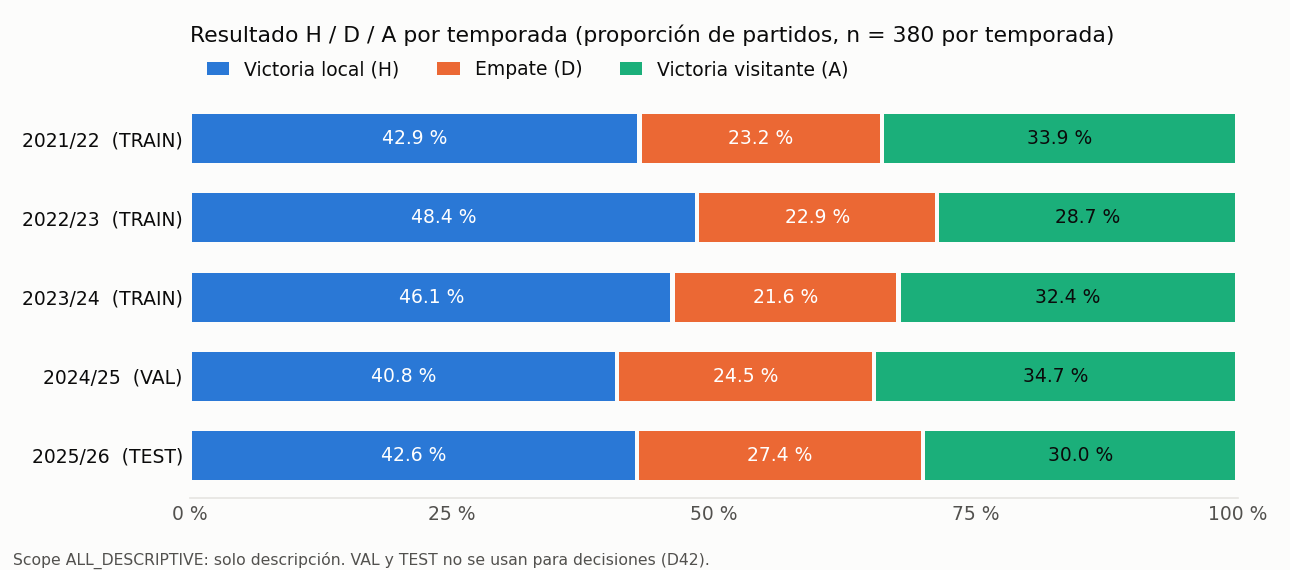

In [5]:
dist = csv("reports/eda/tables/e02_result_distribution__TRAIN.csv")
tab = dist.pivot_table(index="season", columns="result", values="proportion").reindex(columns=["H", "D", "A"])
display((tab * 100).round(1).rename(columns=lambda c: f"% {c}"))
tot = dist[dist.level == "scope_total"].set_index("result")["proportion"]
cita("TRAIN % H", tot["H"] * 100, 45.8, 0.05); cita("TRAIN % D", tot["D"] * 100, 22.5, 0.05); cita("TRAIN % A", tot["A"] * 100, 31.7, 0.05)
figure("reports/eda/figures/e02_result_distribution_by_season__ALL.png")

**Qué muestra.** La proporción de victorias locales, empates y victorias visitantes:
- en la tabla, por temporada de TRAIN y para el total de TRAIN (fila ALL);
- en la figura, para las cinco temporadas (380 partidos cada una, alcance descriptivo según D42).

**Qué observamos.**
- En TRAIN: H 45.8 %, D 22.5 %, A 31.7 %.
- **El empate es la clase minoritaria.**
- Las proporciones cambian entre temporadas. En 2024/25 y 2025/26 hay menos victorias locales y más empates que en TRAIN.

**Qué significa para SCOPE.**
- Las clases no están balanceadas. Un modelo que optimiza probabilidades tenderá a no elegir nunca el empate como clase más probable.
- Por eso se reportan recall y F1 de D, y la accuracy no es criterio único.
- La referencia B1 usa precisamente estas frecuencias de TRAIN.

**Limitación.** La figura usa los 380 partidos de cada temporada, no solo los elegibles; las proporciones de la población elegible difieren en décimas.

### 5.2 Distribución de las features

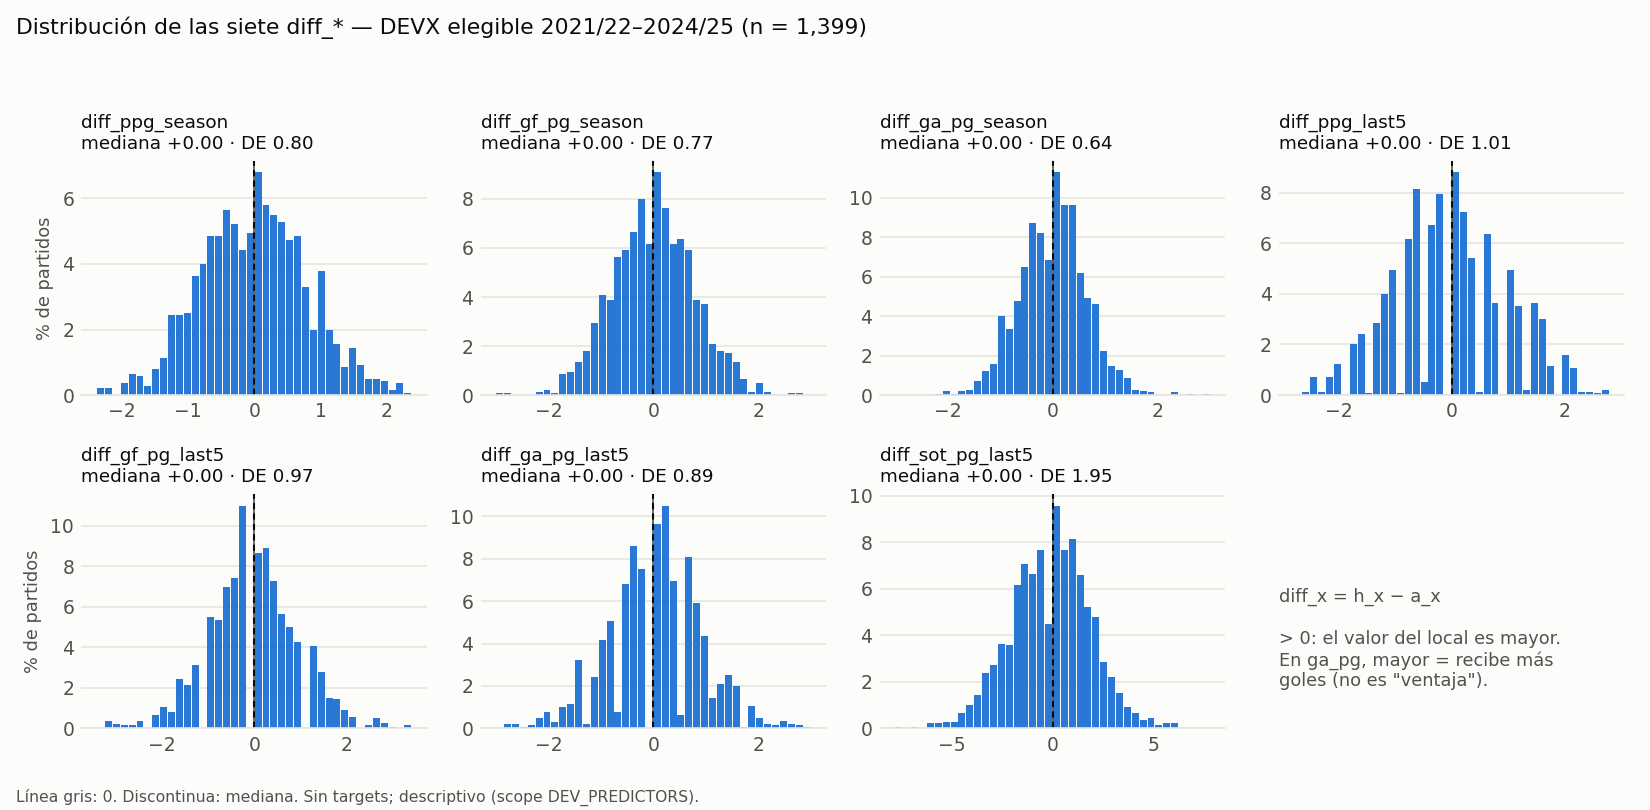

In [6]:
figure("reports/eda/figures/e03_diff_feature_distributions__DEVX.png")

**Qué muestra.** Histogramas de las siete features `diff_` (local − visitante) en los partidos elegibles de 2021/22–2024/25. Son solo predictores, sin targets.

**Qué observamos.**
- Las diferencias están centradas en 0 y son aproximadamente simétricas.
- Las versiones `last5` son mucho más discretas (27–39 valores distintos frente a 477–552 de las de temporada, E3).
- No hay violaciones de dominio.

**Qué significa.**
- Las features son estadísticamente regulares y no necesitan transformaciones.
- La discreción de `last5` produce empates de distancia en KNN y de corte en los árboles, lo que justifica fijar el orden de filas (D30).

### 5.3 Relación de las features con el resultado

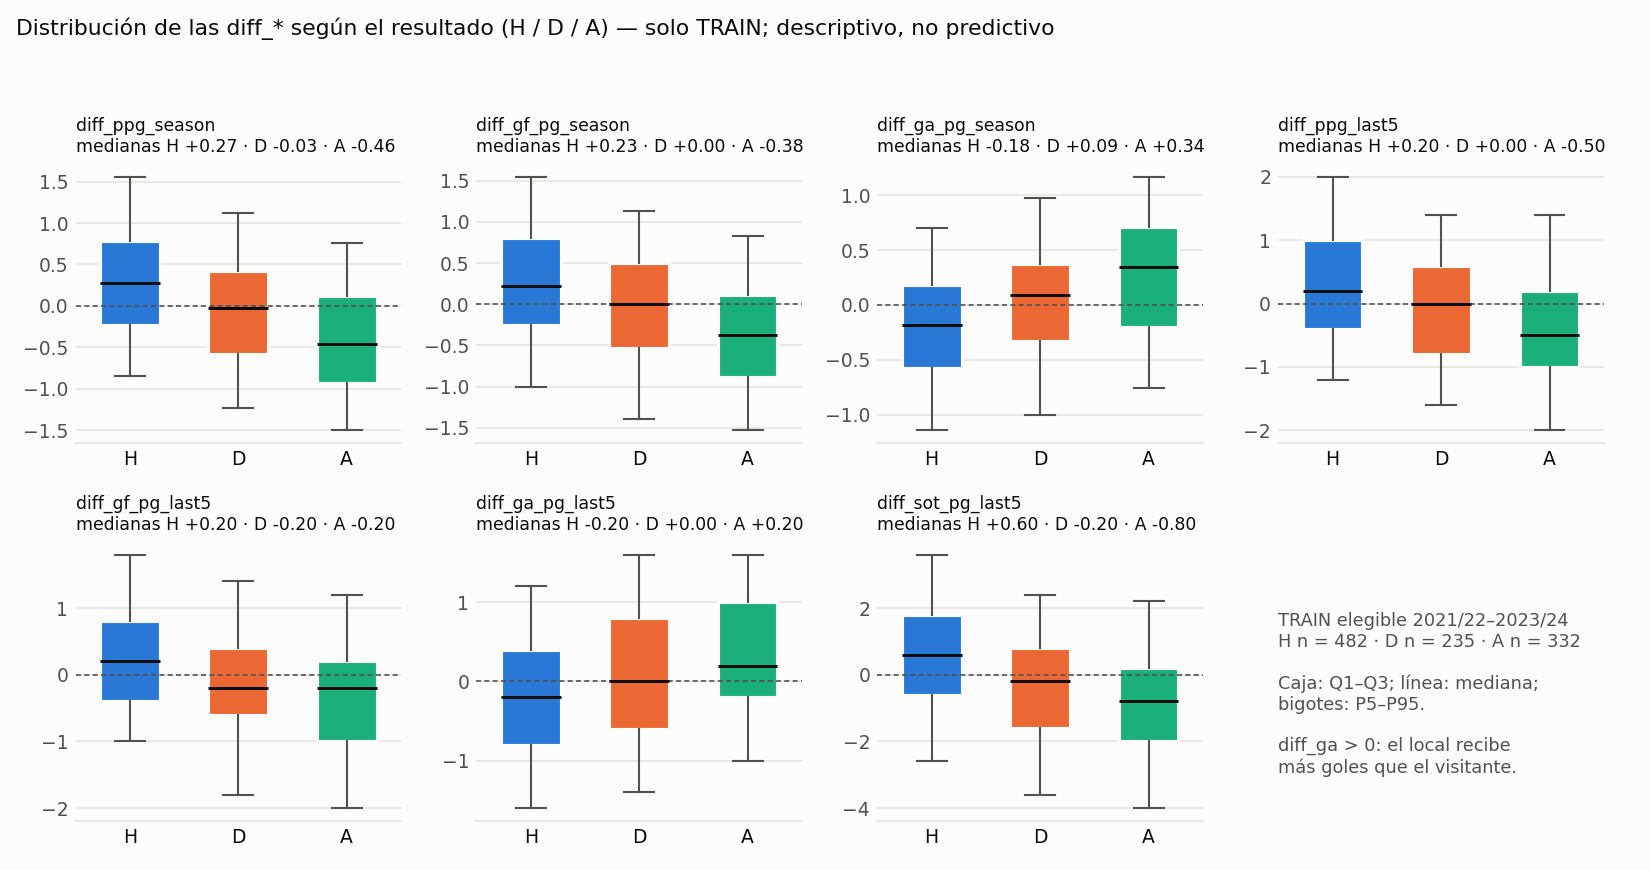

class_1                 D       H        
class_2                 A       A       D
feature                                  
diff_ga_pg_last5  -0.2450 -0.6100 -0.3520
diff_ga_pg_season -0.3620 -0.7930 -0.4140
diff_gf_pg_last5   0.2780  0.6570  0.3690
diff_gf_pg_season  0.4630  0.8810  0.3960
diff_ppg_last5     0.2880  0.7030  0.4180
diff_ppg_season    0.4760  0.9360  0.4580
diff_sot_pg_last5  0.2260  0.7190  0.5020

In [7]:
figure("reports/eda/figures/e04_diff_features_by_result__TRAIN.png")
sep = csv("reports/eda/tables/e04_result_separation__TRAIN.csv")
sep = sep[sep.feature.str.startswith("diff_")].pivot_table(index="feature", columns=["class_1", "class_2"],
                                                            values="standardized_mean_difference")
display(sep.round(3))

**Qué muestra.**
- La figura: diagramas de caja de cada `diff_` según el resultado (solo TRAIN).
- La tabla: la diferencia de medias estandarizada entre pares de clases.

**Qué observamos.**
- Cuando el local tiene mejores estadísticas, gana más: PPG, GF y SOT positivos se asocian a H, y la dirección se invierte en `diff_ga`.
- El **solapamiento entre clases es considerable**.
- Los empates quedan entre H y A, cerca de 0, sin una región propia.
- Las asociaciones con el resultado son moderadas (|r| ≤ 0.41 con la diferencia de goles, E4), mayores en `diff_` y en `season` que en `last5`.

**Qué significa.**
- Las features contienen señal, pero de intensidad moderada. No debe esperarse una precisión alta.
- Separar los empates de H y A será especialmente difícil, como se confirma en §12.

### 5.4 Otros hallazgos del EDA que condicionaron el modelado

| Fase | Hallazgo | Consecuencia metodológica |
|---|---|---|
| E1 | Faltantes solo estructurales (50 partidos inaugurales) | Sin imputación; población elegible sin nulos |
| E5 | `diff = h − a` exactamente: la representación completa HADIFF tiene rango 14 de 21 | **D46:** no usar HADIFF en modelos lineales no regularizados; HA y DIFF como representaciones separadas |
| E6 | `season` y `last5` son idénticas mientras la ventana cubre todo el historial; después divergen | **D47:** sin dependencia lineal exacta; la ventana se decide por evidencia predictiva (P02) |
| E7 | La estabilidad de las features mejora sobre todo hasta 3 partidos previos | **D48:** burn-in k = 3 |
| E8 | `last5` es ≈ 4 veces más responsiva, pero con menor asociación univariada que `season` | P02 se resuelve en modelado (ML-6/ML-7 → **D51**) |
| E9 | Un partido de la fuente con más tiros a puerta que tiros (Q01) | **D49:** se conservan los valores de la fuente con su flag |
| E10 | Cambios de nivel entre temporadas; desplazamiento TRAIN → VALIDATION muy pequeño | Validación temporal estricta; interpretar los resultados por temporada con cautela |

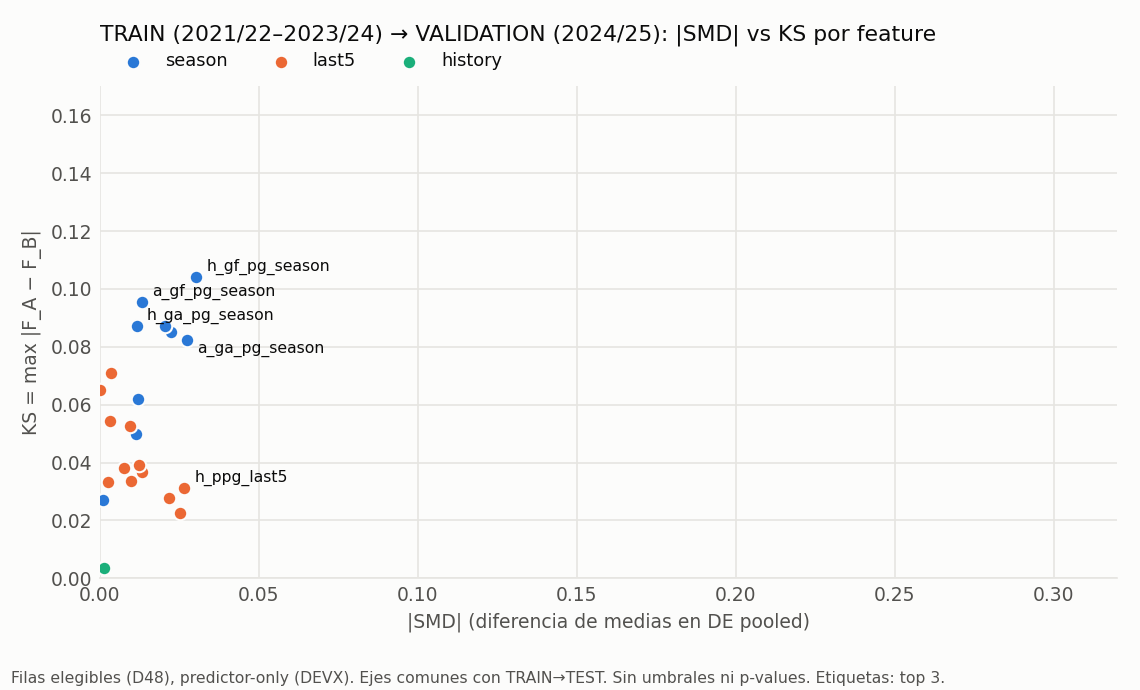

In [8]:
figure("reports/eda/figures/e10_train_val_drift__DEVX.png", width=850)

**Qué muestra.** E10: el cambio estandarizado (SMD) de cada feature entre TRAIN y VALIDATION. Es descriptivo y sin targets.

**Qué observamos.** Los desplazamientos entre TRAIN y VALIDATION son muy pequeños. En el EDA también se describió el desplazamiento TRAIN → TEST, solo con fines descriptivos (D42): TEST tiene niveles algo más bajos y menos dispersos.

**Qué significa.** Las diferencias de rendimiento entre temporadas (§11) no se deben a un cambio grande en las features de entrada. Influyen también la propia aleatoriedad de los resultados y la proporción de empates de cada temporada.

## 6. Outliers y valores faltantes

**Valores faltantes.** Todo el missingness de FEATURES es **estructural**: los 50 primeros partidos de cada temporada no tienen historial previo. El **burn-in k = 3** (D48) define la población elegible: ambos equipos deben haber jugado al menos 3 partidos en la temporada. Excluye 151 partidos (los 50 sin historial y 101 con 1–2 partidos previos) y deja **1,749 partidos sin ningún valor faltante**. Por eso no hay imputación.

**Outliers estadísticos frente a anomalías de calidad.** Son cosas distintas:
- **Outlier estadístico:** un valor extremo pero posible. Por ejemplo, un equipo que ha ganado sus 3 primeros partidos tiene PPG = 3.0. Se detecta con la regla de Tukey (1.5 · IQR) y **no se elimina ni se corrige**: es información real, más ruidosa cuando hay poco historial.
- **Anomalía de calidad:** un dato imposible en la fuente. **Q01:** en el Newcastle – West Ham del 15/08/2021 la fuente registra 8 tiros y 9 tiros a puerta del visitante. Sin verificación externa no se sabe qué valor es erróneo. Por eso **D49** conserva los valores originales con su flag y no aplica ninguna reparación. Solo afecta a features `sot_pg_last5`, que no usa el modelo final.

,features,extremos_tukey,fuera_de_dominio
window,,,
last5,12,147,0
season,9,106,0


,feature,median,q1,q3,min,max,n_below_tukey,n_above_tukey,pct_beyond_tukey,classification
2,diff_ppg_season,0.0000,-0.5714,0.5440,-2.3333,2.2500,3,3,0.5720,valor extremo estadístico (no error); no se el...
5,diff_gf_pg_season,0.0000,-0.5339,0.5385,-3.0000,2.7500,4,3,0.6673,valor extremo estadístico (no error); no se el...
8,diff_ga_pg_season,0.0000,-0.4138,0.4167,-2.1667,3.0000,6,5,1.0486,valor extremo estadístico (no error); no se el...


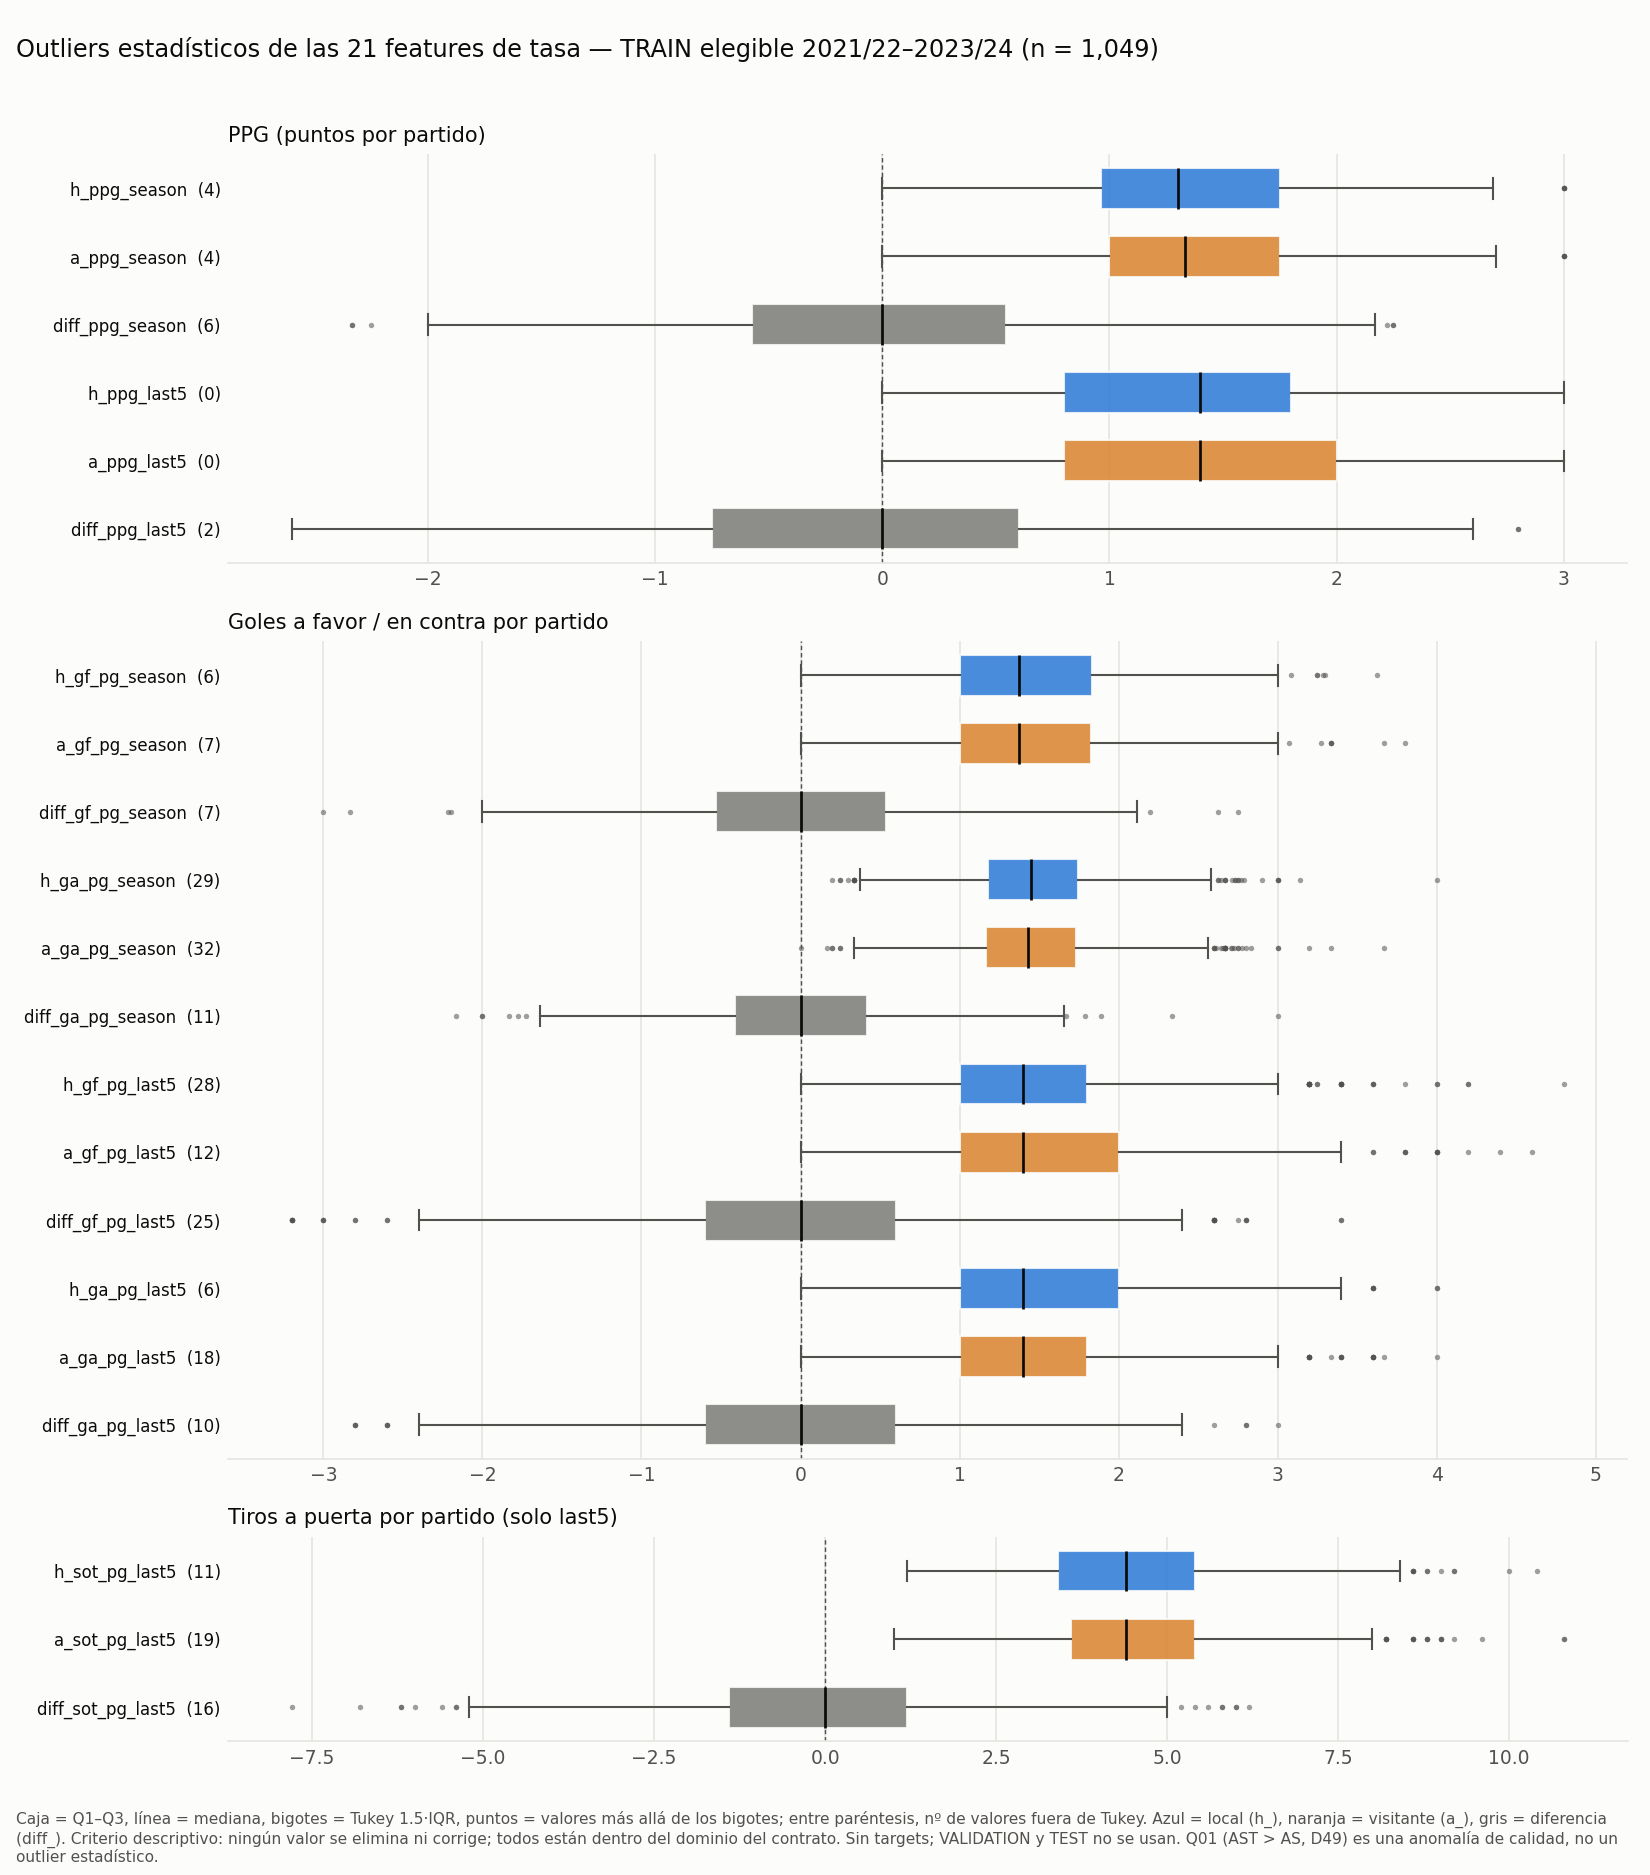

In [9]:
elig = csv("reports/eda/tables/e01_history_eligibility__ALL.csv")
tukey = csv("reports/ml/annex/ml0_outliers_tukey__TRAIN.csv")
resumen = tukey.groupby("window").agg(features=("feature", "count"), extremos_tukey=("n_below_tukey", "sum"),
                                      extremos_sup=("n_above_tukey", "sum"),
                                      fuera_de_dominio=("within_contract_domain", lambda s: int((~s.astype(bool)).sum())))
resumen["extremos_tukey"] += resumen.pop("extremos_sup")
display(resumen)
display(tukey[tukey.feature.isin(r1)][["feature", "median", "q1", "q3", "min", "max", "n_below_tukey", "n_above_tukey",
                                       "pct_beyond_tukey", "classification"]])
cita("extremos Tukey en TRAIN (21 features)", (tukey.n_below_tukey + tukey.n_above_tukey).sum(), 253, 0)
figure("reports/ml/annex/ml0_outliers_boxplot__TRAIN.png")

**Qué muestra.** La regla de Tukey aplicada a las 21 features en los 1,049 partidos elegibles de TRAIN (anexo de ML-0) y el diagrama de caja con los valores extremos visibles.

**Qué observamos.**
- 253 valores fuera de las vallas de Tukey (repartidos en 153 partidos), todos dentro del dominio válido de cada variable.
- En las tres features del modelo final, los extremos son pocos (entre ≈ 0.6 % y ≈ 1.0 % de los partidos por variable).

**Qué significa.** No hay outliers erróneos que eliminar. Los extremos se concentran en partidos con poco historial, ya mitigados por el burn-in.

**Limitación.** No se ejecutó un análisis específico de robustez ante outliers (opcional, Prioridad C del protocolo). La robustez relativa de cada algoritmo se discute solo cualitativamente en §10.

## 7. Matriz de correlaciones

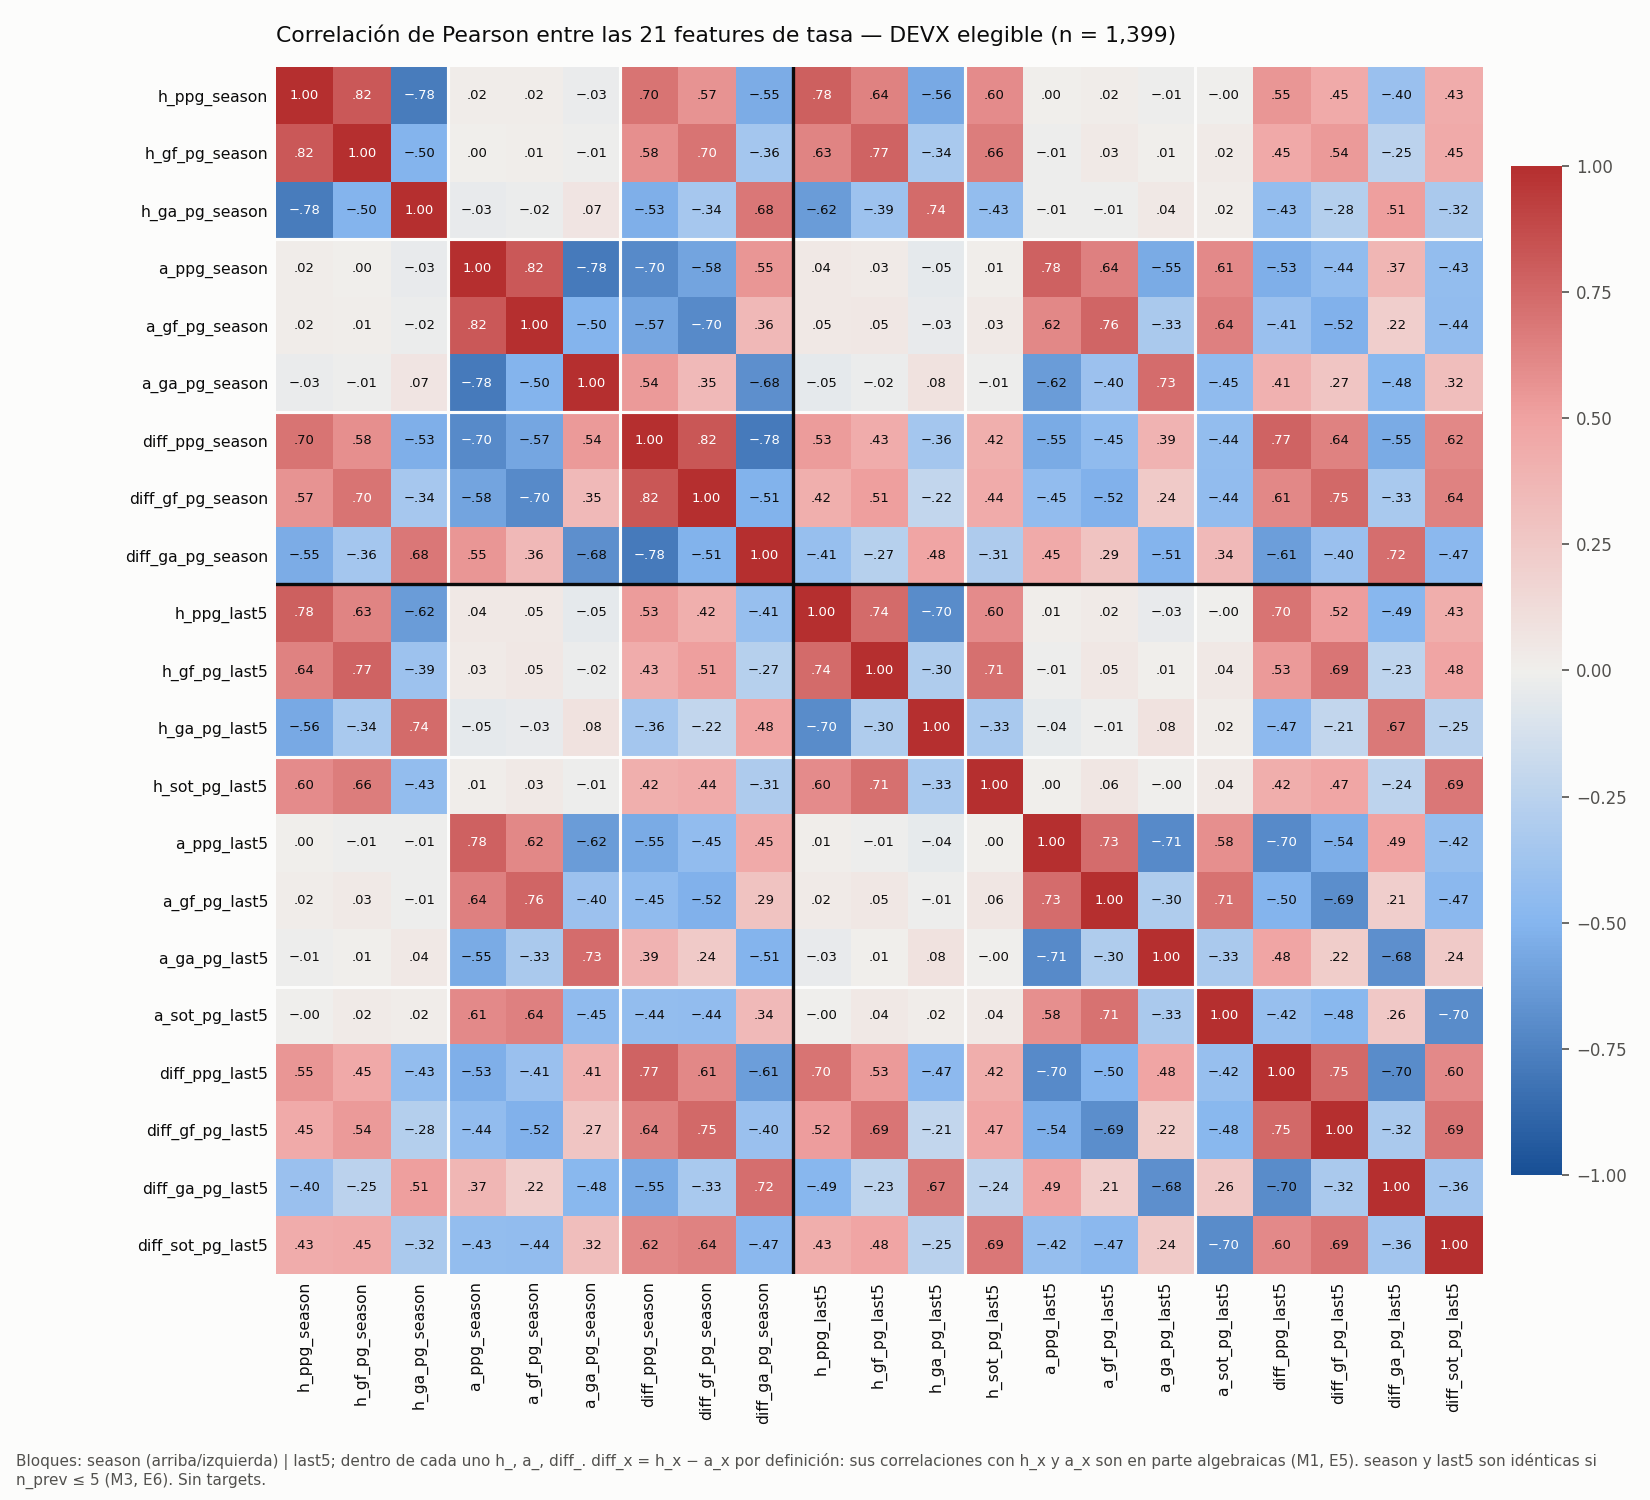

,representation,n_columns,rank,nullity,singular
0,HA,14,14,0,False
4,DIFF,7,7,0,False
8,HADIFF,21,14,7,True


In [10]:
figure("reports/eda/figures/e04_feature_correlation_heatmap__DEVX.png", width=900)
rank = csv("reports/eda/tables/e05_rank_by_representation__DEVX.csv")
display(rank[(rank.scaling == "raw") & (rank.design == "X")][["representation", "n_columns", "rank", "nullity", "singular"]])

**Qué muestra.**
- La figura: la matriz de correlaciones de Pearson entre las 21 features (DEVX, sin targets).
- La tabla: el rango de las tres representaciones posibles (E5).

**Qué observamos.**
- Las versiones local y visitante (`h_x`, `a_x`) están casi incorrelacionadas (|r| ≤ 0.08).
- Su correlación de ≈ ±0.7 con `diff_x` es puramente algebraica.
- PPG se asocia fuertemente con GF (+0.82) y GA (−0.78).
- `season` y `last5` están correlacionadas (0.73–0.78).
- Pearson y Spearman son casi idénticos.

**Qué significa: D46.** Como `diff_x = h_x − a_x` exactamente, la matriz completa HADIFF (`h_` + `a_` + `diff_`, 21 columnas) tiene **rango 14**: 7 columnas son combinaciones lineales exactas de otras (*nullity* 7).
- **Consecuencia:** en un modelo lineal no regularizado los coeficientes no serían identificables. Por eso se **descartó HADIFF** y se trabajó con dos representaciones distintas y no equivalentes:
  - **DIFF** (R1, R2, R5, P04-D5): solo diferencias;
  - **HA** (R3, R4, R6, P04-D10): niveles de local y visitante.
- **Por qué no son equivalentes:** DIFF pierde los niveles absolutos (D22).

**Limitación.** La correlación mide asociación lineal entre predictores; no dice cuánto aporta cada uno a la predicción, que es lo que evalúan las comparaciones P02/P04 (§11).

## 8. Preprocessing

Todas las features son **numéricas y sin faltantes** en la población elegible, así que **no hay imputación ni codificación**. El único preprocesamiento es el **escalado**, y depende de la familia de modelo:

| Familia | Preprocesamiento | Motivo |
|---|---|---|
| Regresión logística (M1) y KNN (M2) | `StandardScaler` (media 0, desviación 1) dentro de un `Pipeline` | Son sensibles a la escala: la regularización L2 y las distancias euclidianas dependen de las unidades de cada variable |
| Decision Tree (M3) y Random Forest (M4) | Ninguno | Los cortes de un árbol son invariantes a transformaciones monótonas |
| Baselines B0/B1 | Ninguno | Solo usan las etiquetas del train |

**Regla anti-leakage.** El scaler se ajusta **solo con los datos de entrenamiento permitidos** y después se aplica sin reajustar a los datos de evaluación:
- en cada fold, con su train;
- para VALIDATION y para el modelo final, con TRAIN_FULL.

Las etapas ML-6 a ML-9 lo **comprobaron en cada ajuste**: el número de muestras, las medias y las desviaciones del scaler coinciden con las del train. En ML-9 se verificó además que el modelo final guarda exactamente las 1,049 filas de TRAIN_FULL.

In [11]:
specs = load_json("reports/ml/ml0_protocol_manifest.json")["models"]
display(pd.DataFrame([{"modelo": k, "clase": v["library_class"].split(".")[-1], "escalado": v["scaling"],
                       "parámetros fijos": json.dumps(v["fixed_params"]), "grid": json.dumps(v["grid"]),
                       "puntos del grid": v["n_grid_points"]} for k, v in specs.items() if k in ("B0", "B1", "M1", "M2", "M3", "M4")]))
pre = load_json("reports/ml/ml7/ml7_run_manifest.json")["preprocessing"]
display(pd.Series(pre, name="preprocesamiento verificado en ML-7 (refit TRAIN_FULL)").to_frame())

,modelo,clase,escalado,parámetros fijos,grid,puntos del grid
0,B0,DummyClassifier,none,"{""strategy"": ""most_frequent""}",{},1
1,B1,DummyClassifier,none,"{""strategy"": ""prior""}",{},1
2,M1,LogisticRegression,StandardScaler (fit solo en train del fold),"{""solver"": ""lbfgs"", ""max_iter"": 5000, ""class_w...","{""C"": [0.01, 0.1, 1.0, 10.0, 100.0], ""penalty""...",5
3,M2,KNeighborsClassifier,StandardScaler (fit solo en train del fold),"{""algorithm"": ""auto"", ""metric"": ""euclidean""}","{""n_neighbors"": [11, 21, 51, 101], ""weights"": ...",8
4,M3,DecisionTreeClassifier,none,"{""random_state"": 42, ""class_weight"": null, ""cr...","{""max_depth"": [2, 3, 4, 6], ""min_samples_leaf""...",12
5,M4,RandomForestClassifier,none,"{""n_estimators"": 150, ""random_state"": 42, ""n_j...","{""max_depth"": [3, 5, 8], ""min_samples_leaf"": [...",9


,preprocesamiento verificado en ML-7 (refit TRAIN_FULL)
M1,StandardScaler fit TRAIN_FULL only (verified)
M2,StandardScaler fit TRAIN_FULL only (verified)
M3,none
M4,none
B0/B1,labels of TRAIN_FULL only


## 9. Baselines

Un modelo solo tiene valor si mejora una referencia sencilla. SCOPE usa dos, que **no cuentan como modelos** para los lineamientos:

- **B0 — clase mayoritaria:** siempre predice H con probabilidad 1.
  - Es útil para las métricas de clasificación: «acertar» sin aprender nada.
  - Su log loss es degenerada: cada partido que no termina en H recibe una penalización enorme. Se reporta como **no informativa**.
- **B1 — prior de clases:** asigna a todos los partidos las frecuencias de H, D y A del train.
  - Es el **baseline probabilístico principal**: un modelo que no supere a B1 en log loss no ha aprendido nada útil de las features.
  - Su ROC-AUC es 0.5 por construcción.

Las frecuencias se calculan siempre con el train correspondiente: el de cada fold, o TRAIN_FULL para VALIDATION y TEST. Nunca con los datos evaluados.

In [12]:
b_cv = csv("reports/ml/ml1/ml1_baseline_fold_metrics.csv")
b_val = csv("reports/ml/ml7/ml7_validation_metrics.csv").query("role == 'BASELINE'")
b_test = csv("reports/ml/ml9/ml9_test_baseline_comparison.csv").query("source in ['B0', 'B1']")
cols = ["log_loss", "brier", "roc_auc_ovr_macro", "accuracy", "f1_macro"]
tabla_b = pd.concat([
    b_cv[b_cv.validation_scope.isin(["CV_T1", "CV_T2"])].assign(alcance=lambda d: d.validation_scope, baseline=lambda d: d.baseline_id),
    b_val.assign(alcance="VALIDATION 2024/25", baseline=lambda d: d.model),
    b_test.assign(alcance="FINAL TEST 2025/26", baseline=lambda d: d.source)])[["alcance", "baseline", *cols]]
display(tabla_b.reset_index(drop=True))

,alcance,baseline,log_loss,brier,roc_auc_ovr_macro,accuracy,f1_macro
0,CV_T1,B0,17.7628,1.0286,0.5000,0.4857,0.2179
1,CV_T1,B1,1.0532,0.6361,0.5000,0.4857,0.2179
2,CV_T2,B0,18.4075,1.0659,0.5000,0.4670,0.2122
3,CV_T2,B1,1.0527,0.6358,0.5000,0.4670,0.2122
4,VALIDATION 2024/25,B0,20.3285,1.1771,0.5000,0.4114,0.1943
5,VALIDATION 2024/25,B1,1.0820,0.6563,0.5000,0.4114,0.1943
6,FINAL TEST 2025/26,B1,1.0906,0.6602,0.5000,0.4200,0.1972
7,FINAL TEST 2025/26,B0,20.0325,1.1600,0.5000,0.4200,0.1972


**Qué observamos.**
- La log loss de B1 es ≈ 1.053 en TRAIN CV, 1.082 en VALIDATION y 1.091 en TEST.
- **Las dos últimas temporadas son intrínsecamente más inciertas:** tienen más empates y menos victorias locales.
- B0 acierta el 41–49 % sin información alguna.

**Qué significa.** Toda comparación entre temporadas debe hacerse **relativa a B1**. Una log loss más alta en TEST no implica por sí misma un peor modelo, porque también empeora la referencia.

## 10. Cuatro modelos

Se evaluaron cuatro familias de scikit-learn, todas con implementación de librería. Las implementaciones manuales de KNN y regresión logística pertenecen al proyecto de Complejidad Computacional del estudiante (D23).

### 10.1 Cómo funciona cada familia

| Modelo | Idea | Fortalezas | Limitaciones |
|---|---|---|---|
| **Regresión logística multinomial (M1)** | Modelo **lineal** en las features: una combinación lineal por clase transformada por *softmax* en probabilidades. Se regulariza con L2 (`C` pequeño = más regularización) | Probabilidades suaves y estables; interpretable; poco propenso al sobreajuste | Solo fronteras lineales; requiere escalado |
| **KNN (M2)** | Para cada partido busca los `k` partidos de train más parecidos (distancia euclidiana sobre features escaladas). Las probabilidades son la proporción de H/D/A entre esos vecinos | No paramétrico: capta relaciones **no lineales** sin suponer una forma; con `k` grande produce probabilidades suavizadas | Sensible a la escala y a la dimensión; `k` depende del tamaño del train; guarda todo el train |
| **Decision Tree (M3)** | Divide el espacio con reglas «si x ≤ umbral». Las probabilidades son las frecuencias de cada hoja | Interpretable; no lineal; no necesita escalado | Probabilidades **muy discretas** (pocas hojas); inestable ante pequeños cambios de datos |
| **Random Forest (M4)** | Promedio de 150 árboles entrenados sobre muestras *bootstrap* y subconjuntos aleatorios de features | No lineal; reduce la varianza del árbol; probabilidades más granulares | Menos interpretable; puede sobreajustar con árboles profundos y muchas features |

**Hiperparámetros.** Son parámetros que no se aprenden de los datos y se fijan antes del ajuste (por ejemplo `C`, `k`, la profundidad o el tamaño mínimo de hoja). Se eligieron **solo con TRAIN CV**: la configuración de menor log loss media en T1 y T2, con grids pequeños y fijados de antemano (ML-0 §14).

### 10.2 Prioridad A: las cuatro familias sobre R1 y R3 (TRAIN CV)

Las cuatro familias se compararon primero sobre dos representaciones base:
- **R1:** 3 diferencias de temporada;
- **R3:** 6 niveles de temporada, local y visitante.

In [13]:
def selected(stage_csv, fam):
    d = csv(stage_csv)
    hp = {"M1": lambda r: f"C={r.selected_C:g}",
          "M2": lambda r: f"k={int(r.selected_n_neighbors)}, {r.selected_weights}",
          "M3": lambda r: f"depth={int(r.selected_max_depth)}, leaf={int(r.selected_min_samples_leaf)}",
          "M4": lambda r: f"depth={int(r.selected_max_depth)}, leaf={int(r.selected_min_samples_leaf)}"}[fam]
    return pd.DataFrame([{"modelo": fam, "representación": r.representation, "hiperparámetros (TRAIN CV)": hp(r),
                          "log loss T1": r.log_loss_T1, "log loss T2": r.log_loss_T2, "log loss media CV": r.log_loss_CV_MEAN}
                         for r in d.itertuples()])


prio_a = pd.concat([selected("reports/ml/ml2/ml2_logreg_selected_configs.csv", "M1"),
                    selected("reports/ml/ml3/ml3_knn_selected_configs.csv", "M2"),
                    selected("reports/ml/ml4/ml4_tree_selected_configs.csv", "M3"),
                    selected("reports/ml/ml5/ml5_rf_selected_configs.csv", "M4")], ignore_index=True)
b1_cv = b_cv.query("baseline_id == 'B1' and validation_scope == 'CV_MEAN'")["log_loss"].item()
prio_a["Δ vs B1 (media CV)"] = prio_a["log loss media CV"] - b1_cv
display(prio_a)
rank_a = csv("reports/ml/ml5/ml5_priority_a_family_ranking.csv")
display(rank_a[["rank", "family", "family_name", "best_representation", "family_score_best_of_R1_R3", "priority_B_candidate_by_ML0_rule"]])
cita("B1 log loss media TRAIN CV", b1_cv, 1.0530, 1e-4)

,modelo,representación,hiperparámetros (TRAIN CV),log loss T1,log loss T2,log loss media CV,Δ vs B1 (media CV)
0,M1,R1,C=0.1,0.9980,0.9548,0.9764,-0.0766
1,M1,R3,C=0.1,0.9995,0.9522,0.9759,-0.0771
2,M2,R1,"k=101, uniform",1.0014,0.9586,0.9800,-0.0730
3,M2,R3,"k=101, distance",1.0006,0.9605,0.9806,-0.0724
4,M3,R1,"depth=3, leaf=50",1.0270,0.9600,0.9935,-0.0595
5,M3,R3,"depth=3, leaf=50",1.0208,0.9733,0.9971,-0.0559
6,M4,R1,"depth=5, leaf=50",0.9920,0.9533,0.9727,-0.0803
7,M4,R3,"depth=3, leaf=25",0.9929,0.9608,0.9769,-0.0761


,rank,family,family_name,best_representation,family_score_best_of_R1_R3,priority_B_candidate_by_ML0_rule
0,1,M4,random_forest,R1,0.9727,True
1,2,M1,multinomial_logistic_regression,R3,0.9759,True
2,3,M2,k_nearest_neighbors,R1,0.9800,False
3,4,M3,decision_tree,R1,0.9935,False


**Qué observamos.**
- **Las cuatro familias superan a B1** en TRAIN CV, con mejoras de log loss de ≈ 0.056 a ≈ 0.080 según familia y representación.
- El ranking por la mejor representación de cada familia es: Random Forest (0.9727, R1), regresión logística (0.9759, R3), KNN (0.9800, R1) y Decision Tree (0.9935, R1).
- Por la regla de ML-0 §14.1, las dos primeras pasaron a la **Prioridad B**: evaluar seis representaciones adicionales para estudiar la ventana `last5`, los tiros a puerta (SOT) y los subconjuntos P04.

**Discusión.**
- **Sobreajuste:** el árbol único tiene las probabilidades más pobres. Con pocas hojas sus probabilidades son muy discretas, y al profundizar se sobreajusta. Random Forest corrige parte de ese problema al promediar.
- **No linealidad:** con R1, los dos modelos no lineales más flexibles (RF y KNN) quedan cerca de la regresión logística. Con las 3 features de R1 no hay evidencia de una ganancia grande por capturar no linealidades.

### 10.3 Prioridad B: representaciones con `last5`, SOT y subconjuntos P04 (TRAIN CV)

In [14]:
rb = csv("reports/ml/ml6/ml6_representation_comparison.csv")
display(rb.pivot_table(index=["representation_family", "representation", "dimension"], columns="model",
                       values="log_loss_CV_MEAN").rename(columns={"M1": "LR · log loss media CV", "M4": "RF · log loss media CV"}))
cita("mejor TRAIN CV LR (P04-D10)", rb.query("model == 'M1' and representation == 'P04-D10'")["log_loss_CV_MEAN"].item(), 0.96753, 1e-5)
cita("mejor TRAIN CV RF (P04-D5)", rb.query("model == 'M4' and representation == 'P04-D5'")["log_loss_CV_MEAN"].item(), 0.96903, 1e-5)

model                                           LR · log loss media CV  RF · log loss media CV
representation_family representation dimension                                                
DIFF                  P04-D5         5                          0.9712                  0.9690
                      R1             3                          0.9764                  0.9727
                      R2             7                          0.9752                  0.9732
                      R5             6                          0.9794                  0.9762
HA                    P04-D10        10                         0.9675                  0.9736
                      R3             6                          0.9759                  0.9769
                      R4             14                         0.9717                  0.9769
                      R6             12                         0.9772                  0.9767

**Qué observamos.**
- En TRAIN CV, los subconjuntos **P04** dieron las menores log loss: P04-D10 en regresión logística (0.96753) y P04-D5 en Random Forest (0.96903). Combinan la temporada con el PPG y el SOT de los últimos 5 partidos.
- Añadir la ventana `last5` de PPG/GF/GA a la temporada (R1→R5, R3→R6) no mejoró de forma consistente.

**Limitación crucial.** Estas diferencias (milésimas de log loss) se obtuvieron con la misma CV usada para elegir hiperparámetros y con solo dos folds. **No son evidencia independiente.** La confirmación correspondía a VALIDATION (§11), y allí **no se sostuvieron**.

## 11. Comparación de métricas

### Métricas utilizadas

- **Log loss multiclase (métrica principal; menor es mejor):** `LL = −(1/N) Σ ln p(resultado real)`.
  - Penaliza fuertemente asignar poca probabilidad a lo que ocurrió.
  - Usa toda la distribución, no solo la clase elegida.
- **Brier multiclase (menor es mejor):** `(1/N) Σ Σ_k (p_k − y_k)²` sobre las tres clases, en rango [0, 2]. Es el error cuadrático de las probabilidades.
- **ROC-AUC One-vs-Rest macro (mayor es mejor):** capacidad de **ordenar** los partidos (se explica en §13). 0.5 = azar.
- **Accuracy, precision, recall y F1:** evalúan la clase elegida por argmax.
  - Se usa **macro-F1**, la media sin ponderar de las tres clases, porque en clases desbalanceadas la accuracy sola engaña.
  - Se presta atención a **recall_D** y **F1_D**.

### 11.1 Tabla comparativa académica — VALIDATION 2024/25

Mejor entrada de cada algoritmo en la shortlist, más los baselines. Todos se reajustaron en TRAIN_FULL y se evaluaron **una vez** sobre los 350 partidos de 2024/25.

,algoritmo,representation,hyperparams,log_loss,brier,roc_auc_ovr_macro,accuracy,precision_macro,recall_macro,f1_macro,recall_D,f1_D,n_matches,log_loss_note
0,Regresión logística,R3,C=0.1,1.0069,0.6035,0.6224,0.5200,0.3478,0.4491,0.3850,0.0000,0.0000,350,NaN
1,KNN,R1,n_neighbors=101|weights=uniform,1.0004,0.6003,0.6575,0.5086,0.3503,0.4356,0.3712,0.0000,0.0000,350,NaN
2,Decision Tree,R1,max_depth=3|min_samples_leaf=50,1.0206,0.6106,0.6259,0.5029,0.3402,0.4329,0.3705,0.0000,0.0000,350,NaN
3,Random Forest,R1,max_depth=5|min_samples_leaf=50,1.0013,0.5996,0.6527,0.5257,0.3556,0.4528,0.3878,0.0000,0.0000,350,NaN
4,B0 (mayoría),NONE,strategy=most_frequent,20.3285,1.1771,0.5000,0.4114,0.1371,0.3333,0.1943,0.0000,0.0000,350,degenerate (no informativa)
5,B1 (prior),NONE,strategy=prior,1.0820,0.6563,0.5000,0.4114,0.1371,0.3333,0.1943,0.0000,0.0000,350,NaN


representation,log loss VALIDATION · R1,log loss VALIDATION · R3
model,,
Regresión logística,1.0076,1.0069
KNN,1.0004,1.0228
Decision Tree,1.0206,1.0361
Random Forest,1.0013,1.0288


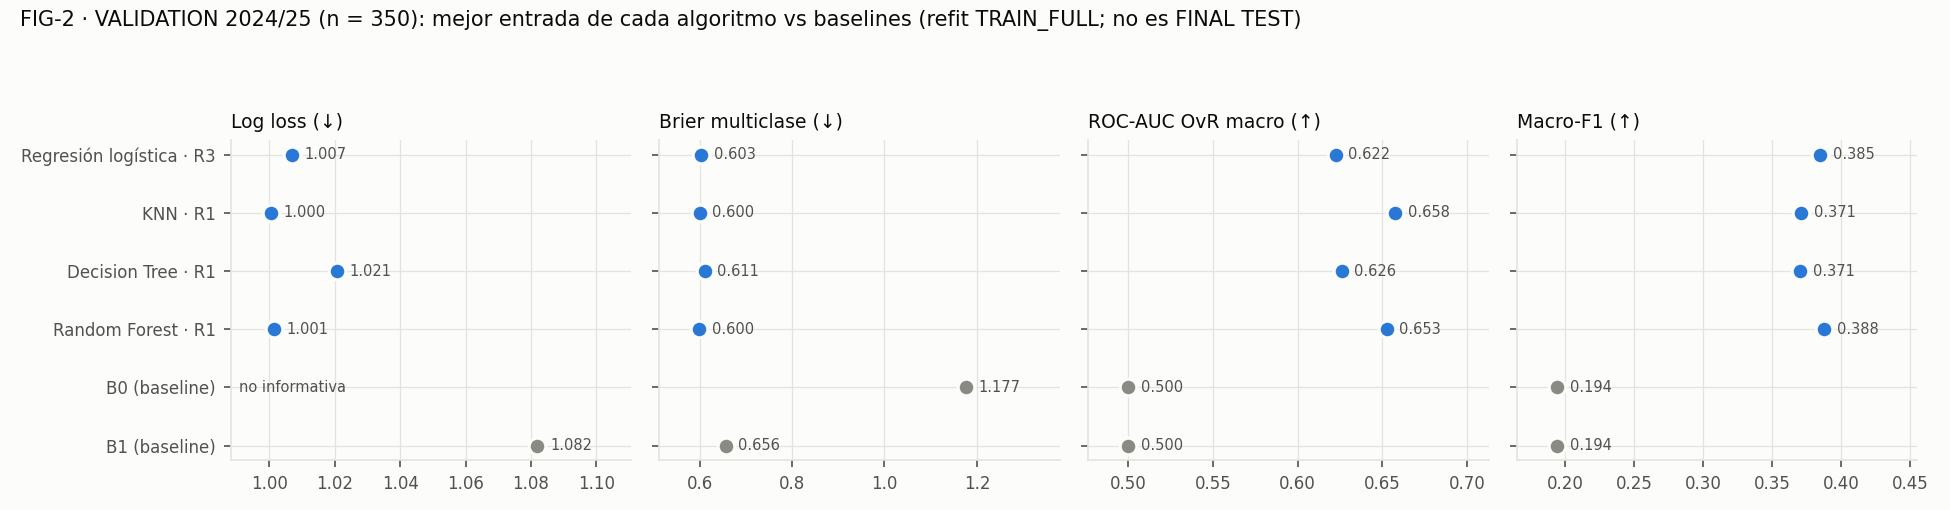

In [15]:
acad = csv("reports/ml/ml7/ml7_academic_model_comparison.csv")
nombres = {"M1": "Regresión logística", "M2": "KNN", "M3": "Decision Tree", "M4": "Random Forest", "B0": "B0 (mayoría)", "B1": "B1 (prior)"}
main = acad[acad.comparison_block == "BEST_SHORTLIST_ENTRY"].assign(algoritmo=lambda d: d.model.map(nombres))
display(main[["algoritmo", "representation", "hyperparams", "log_loss", "brier", "roc_auc_ovr_macro", "accuracy",
              "precision_macro", "recall_macro", "f1_macro", "recall_D", "f1_D", "n_matches", "log_loss_note"]].reset_index(drop=True))
same = acad[acad.comparison_block.str.startswith("SAME_REPRESENTATION")]
display(same.pivot_table(index="model", columns="representation", values="log_loss").rename(index=nombres)
        .rename(columns=lambda c: f"log loss VALIDATION · {c}"))
val = csv("reports/ml/ml7/ml7_validation_metrics.csv").set_index("candidate_id")
cita("VALIDATION KNN-R1", val.loc["M2-R1", "log_loss"], 1.00035, 1e-5)
cita("VALIDATION RF-R1", val.loc["M4-R1", "log_loss"], 1.00131, 1e-5)
cita("VALIDATION LR-R3", val.loc["M1-R3", "log_loss"], 1.00686, 1e-5)
cita("VALIDATION DT-R1", val.loc["M3-R1", "log_loss"], 1.02055, 1e-5)
cita("VALIDATION B1", val.loc["B1", "log_loss"], 1.08198, 1e-5)
figure("reports/ml/ml7/figures/fig2_validation_core_models.png")

**Qué muestra.**
- **La primera tabla y FIG-2:** las métricas de la mejor entrada de cada algoritmo en VALIDATION 2024/25.
- **La segunda tabla:** la comparación más justa entre algoritmos, con la misma representación. Hace falta porque KNN y Decision Tree solo tenían R1 y R3, mientras que regresión logística y Random Forest eligieron entre ocho representaciones.

**Qué observamos.**
- **Frente a B1:** los cuatro algoritmos superan a B1 (1.0820) por ≈ 0.06–0.08 de log loss, y también en Brier, ROC-AUC, accuracy y macro-F1.
- **Las dos mejores:** KNN-R1 (1.00035) y Random Forest-R1 (1.00131), prácticamente empatadas; después regresión logística-R3 (1.00686) y Decision Tree-R1 (1.02055).
- **Con R3:** los modelos no lineales empeoran y la regresión logística es la mejor.
- **Empates:** ningún algoritmo predice empates por argmax (recall_D = 0).

**Qué significa.** Con las 3 diferencias de temporada, un modelo de vecinos o un bosque captan algo más de señal que el modelo lineal, pero las diferencias son pequeñas.

**Limitación.** 350 partidos de una temporada y 20 candidatos comparados, así que el mejor resultado es optimista (sesgo de selección).

### 11.2 TRAIN CV frente a VALIDATION (FIG-5) y ranking completo

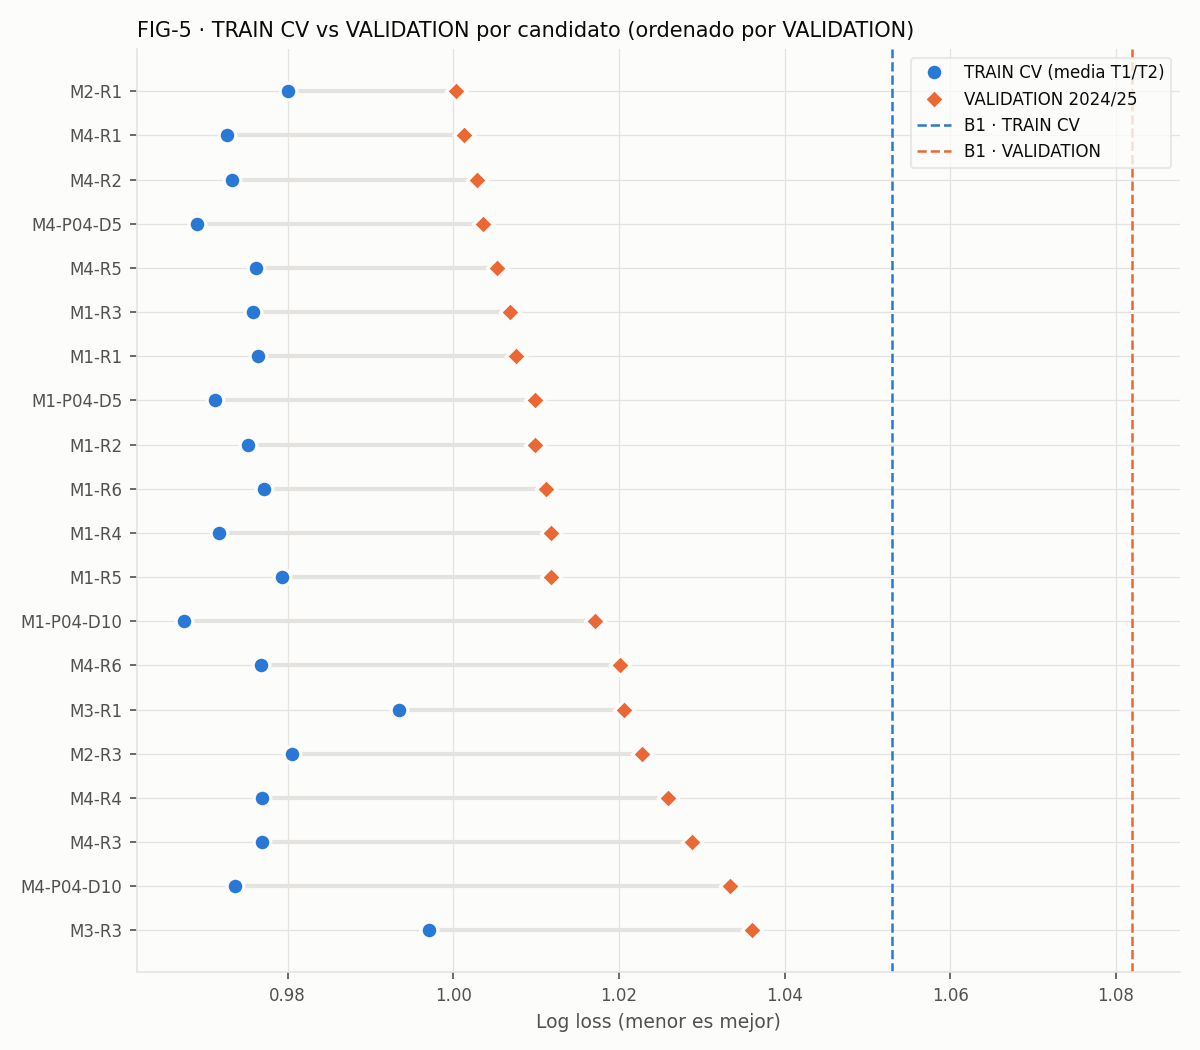

,rank_validation,candidate_id,hyperparams,dimension,log_loss,brier,roc_auc_ovr_macro,f1_macro,delta_vs_B1,boot_vs_best_ci,rank_train_cv
0,1,M2-R1,n_neighbors=101|weights=uniform,3,1.0004,0.6003,0.6575,0.3712,-0.0816,"[0.0, 0.0]",17
1,2,M4-R1,max_depth=5|min_samples_leaf=50,3,1.0013,0.5996,0.6527,0.3878,-0.0807,"[-0.00955244918460491, 0.011947145765239309]",5
2,3,M4-R2,max_depth=5|min_samples_leaf=50,7,1.0028,0.6002,0.6525,0.3871,-0.0791,"[-0.009993884289593323, 0.014881086993845322]",6
3,4,M4-P04-D5,max_depth=5|min_samples_leaf=50,5,1.0036,0.6006,0.6501,0.3920,-0.0784,"[-0.00944387836571088, 0.01633008374060102]",2
4,5,M4-R5,max_depth=3|min_samples_leaf=25,6,1.0053,0.6016,0.6460,0.3942,-0.0767,"[-0.006597726505376332, 0.017664387293494607]",10
5,6,M1-R3,C=0.1,6,1.0069,0.6035,0.6224,0.3850,-0.0751,"[-0.010200181176798922, 0.023712107969253646]",9
6,7,M1-R1,C=0.1,3,1.0076,0.6046,0.6323,0.3853,-0.0744,"[-0.006319131827899531, 0.021457845974262754]",11
7,8,M1-P04-D5,C=0.01,5,1.0099,0.6054,0.6288,0.3859,-0.0721,"[-0.00519463564083965, 0.02436328445053372]",3
8,9,M1-R2,C=0.01,7,1.0099,0.6056,0.6298,0.3891,-0.0721,"[-0.005995481905077127, 0.024373535838275798]",8
9,10,M1-R6,C=0.01,12,1.0112,0.6066,0.6217,0.3855,-0.0707,"[-0.00573018543212476, 0.027479082856166823]",15


In [16]:
figure("reports/ml/ml7/figures/fig5_traincv_vs_validation.png", width=800)
rk = csv("reports/ml/ml7/ml7_validation_ranking.csv")
display(rk[["rank_validation", "candidate_id", "hyperparams", "dimension", "log_loss", "brier", "roc_auc_ovr_macro", "f1_macro",
            "delta_vs_B1", "boot_vs_best_ci", "rank_train_cv"]])

**Qué muestra.**
- **FIG-5:** la log loss de cada uno de los 20 candidatos en TRAIN CV (media de T1/T2) y en VALIDATION, con las referencias de B1.
- **La tabla:** el ranking completo, con el intervalo bootstrap pareado (B = 2,000) de la diferencia frente al primero.

**Qué observamos.**
- **Todo empeora:** todos los candidatos empeoran de TRAIN CV a VALIDATION, y B1 también (+0.029), porque 2024/25 es una temporada más incierta.
- **Cambios de ranking:** las representaciones con más features (P04-D10, R4, R6, R3 en RF) pierden más ventaja sobre B1. Las representaciones simples (R1, R2, R5) la conservan.
- **Diferencias no concluyentes:** 14 de los 19 candidatos no se distinguen del primero con el intervalo bootstrap.

**Sobreajuste.** La diferencia entre TRAIN CV y VALIDATION mezcla tres factores: el tamaño de train (350/700 frente a 1,049), el cambio de temporada y la incertidumbre. No se atribuye solo al sobreajuste. Aun así, la pérdida de ventaja de las configuraciones más complejas es coherente con un sobreajuste a los folds de TRAIN CV.

### 11.3 P02 y P04 en VALIDATION

In [17]:
p02 = csv("reports/ml/ml7/ml7_p02_validation_comparisons.csv")
p04 = csv("reports/ml/ml7/ml7_p04_validation_comparisons.csv")
cols = ["model", "question", "comparison", "cv_delta_T1", "cv_delta_T2", "val_delta_log_loss", "val_boot_ci_2_5", "val_boot_ci_97_5",
        "cv_both_folds_and_validation_lower"]
display(pd.concat([p02[cols], p04[cols]], ignore_index=True))

,model,question,comparison,cv_delta_T1,cv_delta_T2,val_delta_log_loss,val_boot_ci_2_5,val_boot_ci_97_5,cv_both_folds_and_validation_lower
0,M1,P02-A_window,R1->R5,0.0012,0.0047,0.0042,-0.0027,0.0108,False
1,M1,P02-A_window,R3->R6,-0.0018,0.0044,0.0044,-0.0041,0.0126,False
2,M1,P02-B_sot,R5->R2,-0.0027,-0.0056,-0.0019,-0.0087,0.0051,True
3,M1,P02-B_sot,R6->R4,-0.0040,-0.0070,0.0006,-0.0071,0.0085,False
4,M1,P02-C_full_block,R1->R2,-0.0015,-0.0009,0.0023,-0.0072,0.0119,False
5,M1,P02-C_full_block,R3->R4,-0.0058,-0.0026,0.0049,-0.0068,0.0168,False
6,M4,P02-A_window,R1->R5,0.0080,-0.0009,0.0040,-0.0040,0.0120,False
7,M4,P02-A_window,R3->R6,0.0061,-0.0063,-0.0087,-0.0199,0.0017,False
8,M4,P02-B_sot,R5->R2,-0.0051,-0.0007,-0.0025,-0.0109,0.0057,True
9,M4,P02-B_sot,R6->R4,-0.0014,0.0016,0.0058,-0.0017,0.0136,False


**Qué muestra.** Las comparaciones planificadas entre representaciones con la misma familia de modelo. Δ = log loss de la nueva − log loss de la referencia; negativo es mejora.

**Qué observamos.**
- **Ventana `last5` (P02-A):** ninguna de las cuatro comparaciones mejora a la vez en ambos folds y en VALIDATION.
- **SOT (P02-B):** solo mejora en la variante DIFF (R5→R2), con intervalos que incluyen 0.
- **Subconjuntos P04:** las ventajas de TRAIN CV **se invirtieron** en VALIDATION.

**Qué significa.**
- Bajo los modelos, variables y temporadas de v0.1 no hubo evidencia suficientemente consistente para incorporar el bloque `last5`: P02 se cerró en **D51** con la lectura parsimoniosa, solo temporada.
- Los subconjuntos P04 no se adoptaron como representación predictiva (**D52**). Siguen siendo válidos para el estudio de coste computacional de Complejidad.

### 11.4 Resultado definitivo — FINAL TEST 2025/26 (modelo congelado KNN-R1)

> Los resultados siguientes proceden de la **única** evaluación sobre FINAL TEST (ML-9). Se realizó con el modelo ya congelado, cuyas predicciones se sellaron antes de leer los resultados reales. **No se usaron para elegir ni ajustar nada.**

Predicciones selladas: ml9_test_predictions_sealed.csv · SHA-256 f67d69b2f38bec90bf0a05cda6d88a4b6433ac3d7847dcdbadfd7f225cdbb7e6 · filas 350 · selladas 2026-11-05T06:34:31.849035Z · etiquetas leídas antes del sello: False


,source,role,coverage,log_loss,brier,roc_auc_ovr_macro,roc_auc_D,accuracy,f1_macro,recall_D,delta_log_loss_knn_minus_this,boot_ci_knn_minus_this
0,M2-R1,modelo final congelado,350/350,1.0452,0.6296,0.6000,0.4998,0.4743,0.3421,0.0000,0.0000,NaN
1,B1,baseline,350/350,1.0906,0.6602,0.5000,0.5000,0.4200,0.1972,0.0000,-0.0455,"[-0.08017597418093945, -0.011085335078288539]"
2,MARKET_PRE,benchmark externo principal (pre-partido),350/350,1.0162,0.6111,0.6289,0.5105,0.4971,0.3728,0.0000,0.0289,"[0.0022543984993900943, 0.05395780727416877]"
3,MARKET_CLOSE,benchmark externo secundario (cierre),350/350,1.0136,0.6094,0.6350,0.5254,0.4943,0.3723,0.0000,0.0315,"[0.0035755375713998417, 0.057904486012731494]"


,scope,eval_season,n_train,n_eval,share_H,share_D,share_A,knn_log_loss,b1_log_loss,knn_minus_b1,market_pre_log_loss
0,CV_T1,2022/23,350,350,0.4857,0.2229,0.2914,1.0014,1.0532,-0.0519,NaN
1,CV_T2,2023/24,700,349,0.4670,0.2206,0.3123,0.9586,1.0527,-0.0941,NaN
2,CV_MEAN,2022/23 + 2023/24 (media),350/700,350/349,NaN,NaN,NaN,0.9800,1.0530,-0.0730,NaN
3,VALIDATION_2024_25,2024/25,1049,350,0.4114,0.2457,0.3429,1.0004,1.0820,-0.0816,0.9815
4,FINAL_TEST_2025_26,2025/26,1049,350,0.4200,0.2800,0.3000,1.0452,1.0906,-0.0455,1.0162


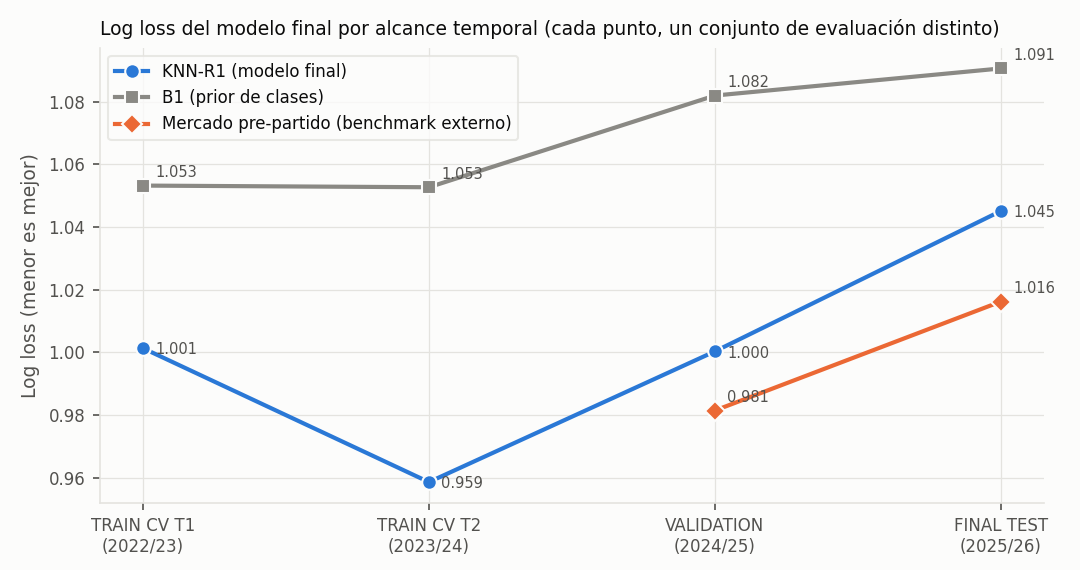

In [18]:
seal = load_json("reports/ml/ml9/ml9_prediction_seal.json")
print("Predicciones selladas:", seal["file"], "· SHA-256", seal["sha256"], "· filas", seal["n_rows"],
      "· selladas", seal["sealed_utc"], "· etiquetas leídas antes del sello:", seal["labels_loaded_before_seal"])
assert sha256(rp("reports/ml/ml9/" + seal["file"])) == seal["sha256"]
test_mk = csv("reports/ml/ml9/ml9_test_market_benchmark.csv")
display(test_mk[["source", "role", "coverage", "log_loss", "brier", "roc_auc_ovr_macro", "roc_auc_D", "accuracy", "f1_macro",
                 "recall_D", "delta_log_loss_knn_minus_this", "boot_ci_knn_minus_this"]])
tb = csv("reports/ml/ml9/ml9_test_baseline_comparison.csv").set_index("source")
tm = test_mk.set_index("source")
cita("TEST log loss KNN-R1", tm.loc["M2-R1", "log_loss"], 1.0452, 1e-4)
cita("TEST Brier KNN-R1", tm.loc["M2-R1", "brier"], 0.6296, 1e-4)
cita("TEST ROC-AUC macro", tm.loc["M2-R1", "roc_auc_ovr_macro"], 0.600, 5e-4)
cita("TEST accuracy", tm.loc["M2-R1", "accuracy"], 0.474, 5e-4)
cita("TEST macro-F1", tm.loc["M2-R1", "f1_macro"], 0.342, 5e-4)
cita("TEST B1", tm.loc["B1", "log_loss"], 1.0906, 1e-4)
cita("TEST mercado pre", tm.loc["MARKET_PRE", "log_loss"], 1.0162, 1e-4)
cita("TEST mercado cierre", tm.loc["MARKET_CLOSE", "log_loss"], 1.0136, 1e-4)
cita("mejora relativa vs B1 (%)", tb.loc["B1", "relative_log_loss_improvement_of_knn_vs_B1"] * 100, 4.17, 0.01)
comp = csv("reports/ml/ml9/ml9_traincv_validation_test_comparison.csv")
display(comp[["scope", "eval_season", "n_train", "n_eval", "share_H", "share_D", "share_A", "knn_log_loss", "b1_log_loss",
              "knn_minus_b1", "market_pre_log_loss"]])
figure("reports/ml/ml9/figures/fig6_logloss_by_scope.png", width=800)

**Qué muestra.**
- **La primera tabla:** las métricas de KNN-R1 en FINAL TEST frente a B1 y al mercado. Las cuotas son un **benchmark externo**, no una predicción del modelo.
- **La segunda tabla y la figura:** la evolución de la log loss del modelo final, de B1 y del mercado por alcance temporal.

**Qué observamos.**
- **Frente a B1:** KNN-R1 obtiene 1.0452, frente a 1.0906. Es una mejora de 0.045, un **4.2 % relativo**, con un intervalo bootstrap que excluye 0.
- **Frente al mercado:** queda **por detrás** del pre-partido (1.0162) y del cierre (1.0136). En TEST el intervalo de esa diferencia excluye 0.
- **Frente a VALIDATION:** la log loss empeora (1.0004 → 1.0452).
- **Una temporada más difícil:** 2025/26 tiene un 28 % de empates, la proporción más alta, y también empeoran B1 y el mercado.
- **Pérdida relativa real:** aun así, la ventaja de KNN sobre B1 se reduce casi a la mitad.

**Qué significa.** El modelo generaliza en el sentido de que sigue superando al prior en una temporada nunca vista, pero con menos ventaja que en validación. El valor de VALIDATION era optimista por la selección entre 20 candidatos.

**Limitación.** No pueden separarse con estos datos el cambio temporal de la liga, el modelo estático (sin reentrenar durante dos temporadas), el `k` elegido con poco train y la variación de 350 partidos.

## 12. Matriz de confusión

La matriz de confusión cruza la clase **real** (filas) con la clase **predicha** por argmax (columnas). La diagonal son los aciertos.

- **Precision de una clase:** de las veces que se predijo, cuántas fueron correctas.
- **Recall de una clase:** de las veces que ocurrió, cuántas se predijeron.

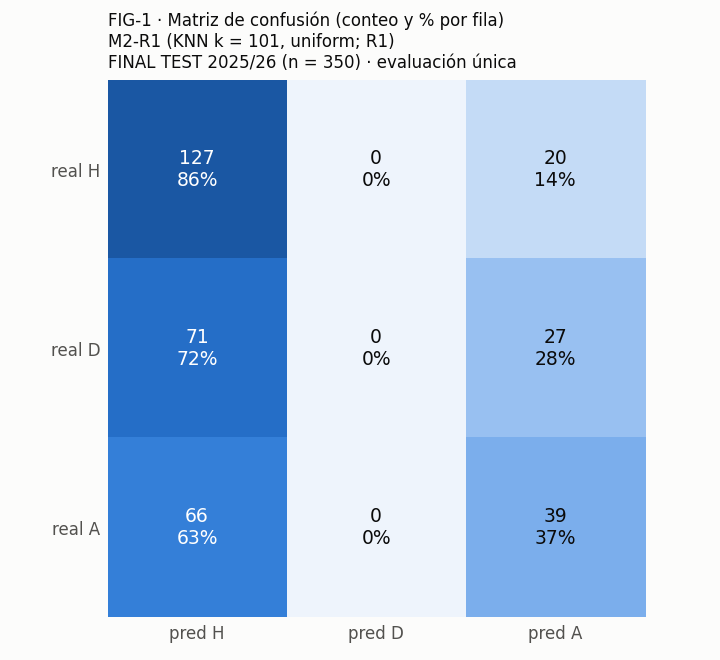

predicha,H,D,A
real,,,
H,127,0,20
D,71,0,27
A,66,0,39


,precision,recall,F1,reales,predichos
H,0.4811,0.8639,0.6180,147,264
D,0.0000,0.0000,0.0000,98,0
A,0.4535,0.3714,0.4084,105,86


In [19]:
figure("reports/ml/ml9/figures/fig1_confusion_matrix_test.png", width=520)
cm = csv("reports/ml/ml9/ml9_test_confusion_matrix.csv").pivot_table(index="true_class", columns="pred_class", values="count")
display(cm.reindex(index=["H", "D", "A"], columns=["H", "D", "A"]).astype(int).rename_axis(index="real", columns="predicha"))
m9 = csv("reports/ml/ml9/ml9_test_metrics.csv").iloc[0]
display(pd.DataFrame({c: {"precision": m9[f"precision_{c}"], "recall": m9[f"recall_{c}"], "F1": m9[f"f1_{c}"],
                          "reales": int(m9[f"support_{c}"]), "predichos": int(m9[f"n_predicted_{c}"])} for c in "HDA"}).T.astype({"reales": int, "predichos": int}))
cita("TEST predicciones D", m9["n_predicted_D"], 0, 0)
cita("TEST recall H", m9["recall_H"], 0.864, 5e-4)

**Qué muestra.** La matriz de confusión de KNN-R1 sobre los 350 partidos de FINAL TEST 2025/26 y sus métricas por clase. La versión de VALIDATION está en `reports/ml/ml7/figures/fig1_confusion_matrix_provisional.png`.

**Qué observamos.**
- **Empates:** el modelo **no predijo ningún empate**. Los 98 empates reales se clasificaron como H (72 %) o como A (28 %).
- **Locales:** predice H en exceso (264 veces para 147 locales reales; recall 0.86, precision 0.48).
- **Visitantes:** recupera solo el 37 % de las victorias visitantes.

**Qué significa.**
- En el fútbol el empate rara vez es el resultado individual más probable. En TEST, P(D) del modelo nunca supera 0.32, así que argmax nunca lo elige.
- **No es un error de implementación:** el mercado tampoco elige nunca el empate como favorito (EDA E2m).
- La utilidad del modelo está en sus **probabilidades**, no en una predicción categórica de empate.

**Limitación.** No se introdujeron umbrales especiales ni pesos de clase para forzar predicciones de empate, porque deteriorarían la calibración. La predicción de empates sigue siendo una limitación importante de v0.1.

## 13. ROC-AUC

**Qué es.** La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos frente a la de falsos positivos. El área bajo la curva (**AUC**) es la probabilidad de que un partido elegido al azar de la clase positiva reciba mayor probabilidad que uno de la clase negativa.
- **AUC = 0.5:** el modelo no ordena mejor que el azar.
- **AUC = 1:** el orden es perfecto.

**One-vs-Rest (OvR).** Con tres clases se calcula un AUC binario por clase (H contra no-H, D contra no-D, A contra no-A) usando la columna de probabilidad de esa clase. La **macro** es su media sin ponderar.
- Mide **discriminación**, no calibración.
- Se calcula con las probabilidades, no con la clase predicha.

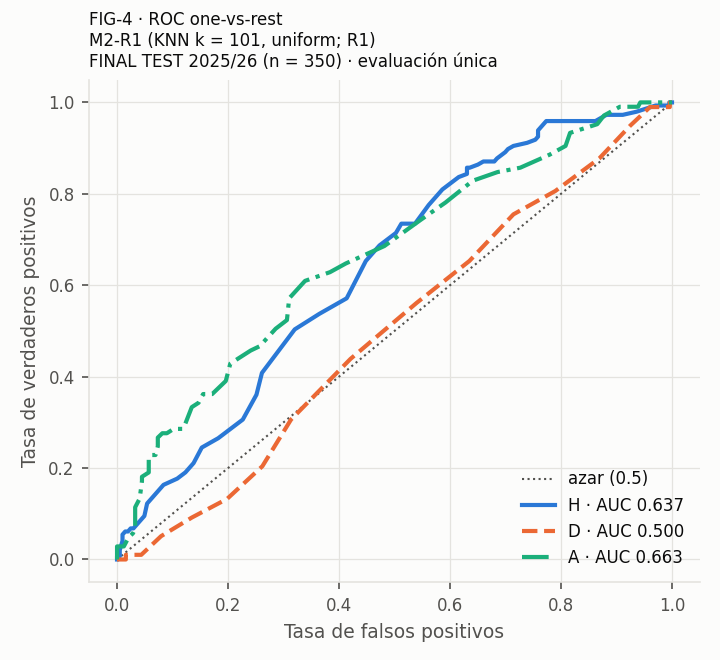

,VALIDATION 2024/25,FINAL TEST 2025/26
H,0.6765,0.6370
D,0.5833,0.4998
A,0.7128,0.6632
ovr_macro,0.6575,0.6000


In [20]:
figure("reports/ml/ml9/figures/fig4_roc_ovr_test.png", width=520)
v = val.loc["M2-R1"]
display(pd.DataFrame({"VALIDATION 2024/25": {c: v[f"roc_auc_{c}"] for c in ["H", "D", "A", "ovr_macro"]},
                      "FINAL TEST 2025/26": {c: m9[f"roc_auc_{c}"] for c in ["H", "D", "A", "ovr_macro"]}}))
cita("TEST AUC_D", m9["roc_auc_D"], 0.500, 5e-4)

**Qué muestra.** Las curvas ROC por clase de KNN-R1 en FINAL TEST y la comparación de AUC con VALIDATION.

**Qué observamos.**
- **H y A:** el modelo discrimina moderadamente (AUC ≈ 0.64 y 0.66).
- **D:** el AUC en TEST es **≈ 0.500**: las probabilidades de empate **no ordenan los empates mejor que el azar**. En VALIDATION era 0.583.
- **Macro:** baja de 0.658 a 0.600.

**Qué significa.** Las tres diferencias de temporada informan sobre quién es mejor equipo, y eso desplaza la probabilidad entre H y A, pero no identifican qué partidos acabarán en empate.

**Limitación.** El AUC por clase con 98 empates tiene una incertidumbre apreciable.

## 14. Calibración

Un modelo está **calibrado** si, de todos los partidos a los que asigna P(H) ≈ 0.6, alrededor del 60 % terminan en H.

- **Curvas de fiabilidad:** agrupan las predicciones en 10 bins por cuantiles y comparan la probabilidad media predicha con la frecuencia observada. La diagonal es la calibración perfecta.
- **Calibración global (*calibration-in-the-large*, CITL):** la diferencia entre la probabilidad media predicha y la frecuencia real de cada clase. Positivo = se sobreestima.
- **ECE:** el error de calibración medio ponderado por bin. Es descriptivo.
- **Log loss y Brier** combinan calibración y discriminación.

No se aplicó ninguna recalibración posterior (ML-0 §15): las probabilidades son las del modelo congelado.

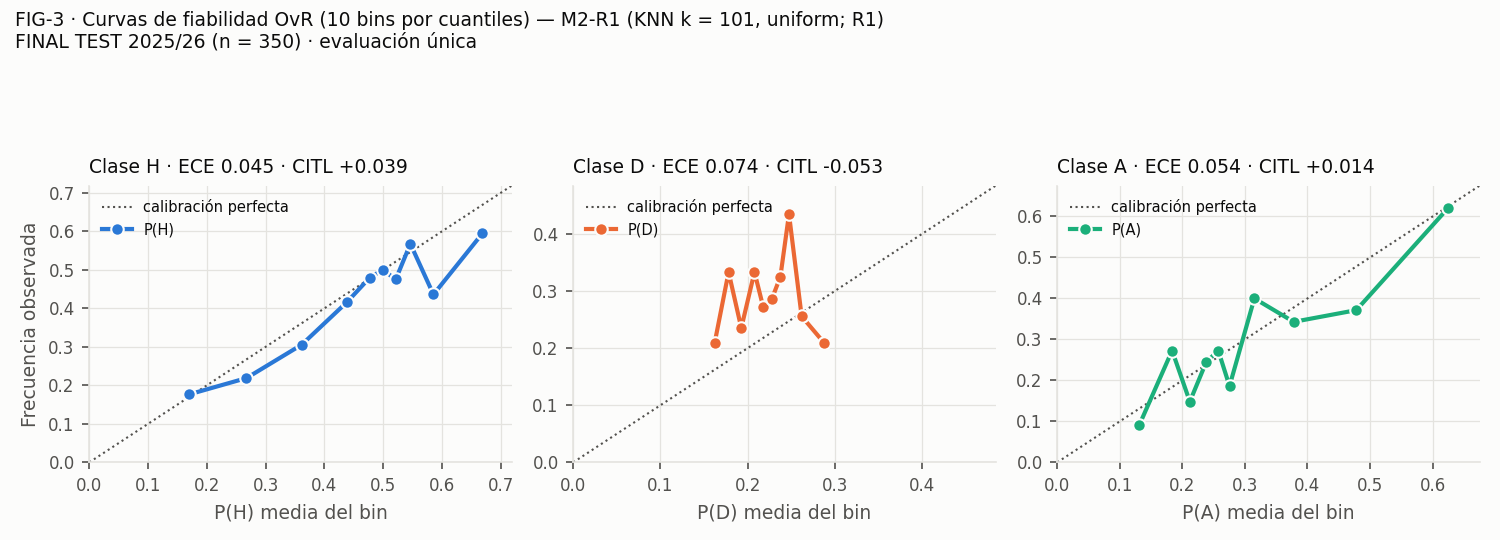

,class,p_mean,observed_freq,citl,ece,p_min,p_max
0,H,0.4591,0.4200,0.0391,0.0454,0.1287,0.7723
1,D,0.2266,0.2800,-0.0534,0.0743,0.1287,0.3168
2,A,0.3144,0.3000,0.0144,0.0541,0.0891,0.6931


In [21]:
figure("reports/ml/ml9/figures/fig3_calibration_test.png")
cal = csv("reports/ml/ml9/ml9_test_calibration.csv")
display(cal[cal.kind == "summary"][["class", "p_mean", "observed_freq", "citl", "ece", "p_min", "p_max"]].reset_index(drop=True))
cita("TEST CITL D", m9["citl_D"], -0.053, 5e-4)

**Qué muestra.** Las curvas de fiabilidad OvR de KNN-R1 en FINAL TEST y la calibración global por clase. La versión de VALIDATION está en `reports/ml/ml7/figures/fig3_calibration_provisional.png`.

**Qué observamos.**
- **H y A:** las curvas siguen aproximadamente la diagonal, con ruido.
- **Locales:** el modelo sobreestima ligeramente H (CITL +0.039).
- **Empates:** **subestima D**: predice en media ≈ 22.7 % de empates frente al 28 % real (CITL −0.053), y sus P(D) quedan comprimidas entre 0.13 y 0.32.
- **ECE:** de 0.045 a 0.074.

**Qué significa.** Las probabilidades son razonablemente calibradas para H y A. El modelo conserva el prior de empates de TRAIN (≈ 22.5 %), y una temporada con más empates queda sistemáticamente infraestimada.

**Limitación.** La calibración no se corrige en v0.1. Hacerlo exigiría un conjunto propio y una decisión previa al freeze, nunca TEST.

## 15. Selección y justificación

La selección siguió un **protocolo preregistrado** (ML-0) y nunca usó FINAL TEST.

| Etapa | Qué se hizo | Resultado |
|---|---|---|
| **ML-0** | Protocolo, splits, representaciones, grids, métricas y regla de selección, fijados **antes** de entrenar | Jerarquía: log loss → Brier/calibración → ROC-AUC y macro-F1 → parsimonia |
| **ML-1** | Motor de métricas propio con tests; baselines B0/B1 | B1 = referencia probabilística |
| **ML-2 a ML-5** | Prioridad A: las 4 familias sobre R1 y R3, hiperparámetros por TRAIN CV | Las 4 superan a B1; RF y LR pasan a Prioridad B |
| **ML-6** | Prioridad B: 6 representaciones más con RF y LR | En CV destacan los subconjuntos P04 |
| **ML-7** | Shortlist cerrada de 20 candidatos, reajuste en TRAIN_FULL y una evaluación en VALIDATION | KNN-R1 es el primero; las ventajas de P04 y `last5` no se sostienen |
| **ML-8** | Selección literal, cierre de P02/P04/P06, política de refit y freeze del modelo | **D50–D54** |
| **ML-9** | Una única evaluación del modelo congelado en FINAL TEST, con predicciones selladas | Resultados de §11.4 |

In [22]:
final = csv("reports/ml/ml8/ml8_final_candidate_comparison.csv")
display(final[["candidate_id", "hyperparams", "log_loss", "brier", "roc_auc_ovr_macro", "roc_auc_D", "accuracy", "f1_macro",
               "ece_H", "ece_D", "ece_A", "delta_log_loss_vs_selected", "boot_ci_2_5_vs_selected", "boot_ci_97_5_vs_selected",
               "rank_validation", "rank_train_cv", "train_cv_stable_across_folds", "role_in_ML8"]])
cita("Δ log loss RF-R1 − KNN-R1 (VALIDATION)", final.set_index("candidate_id").loc["M4-R1", "delta_log_loss_vs_selected"], 0.00096, 1e-5)
dl = rp("docs/DECISION_LOG.md").read_text(encoding="utf-8")
dec = []
for line in dl.splitlines():
    m = re.match(r"\| (D4[2-9]|D5[0-4]) \| (.*?) \|", line)
    if m:
        t = re.search(r"\*\*(.+?)\*\*", m.group(2))
        dec.append({"ID": m.group(1), "decisión": (t.group(1) if t else m.group(2))[:110]})
display(pd.DataFrame(dec))
spec = load_json("reports/ml/ml8/ml8_final_model_spec.json")
display(pd.Series({"candidato": spec["candidate_id"], "features (orden)": ", ".join(spec["features_ordered"]),
                   "hiperparámetros": json.dumps(spec["hyperparameters"]), "entrenamiento": f"{spec['allowed_training_data']['seasons']} · n = {spec['allowed_training_data']['n']}",
                   "política de refit": f"({spec['refit_policy']['option']}) {spec['refit_policy']['name']}",
                   "calibración / thresholds / class weights": f"{spec['calibration']} / {spec['thresholds']} / {spec['class_weights']}",
                   "orden de clases": spec["class_order"], "artefacto": spec["artifact"]["path"], "SHA-256 artefacto": spec["artifact"]["sha256"],
                   "freeze": spec["freeze_date"]}, name="modelo final congelado (ML-8)").to_frame())

,candidate_id,hyperparams,log_loss,brier,roc_auc_ovr_macro,roc_auc_D,accuracy,f1_macro,ece_H,ece_D,ece_A,delta_log_loss_vs_selected,boot_ci_2_5_vs_selected,boot_ci_97_5_vs_selected,rank_validation,rank_train_cv,train_cv_stable_across_folds,role_in_ML8
0,M2-R1,n_neighbors=101|weights=uniform,1.0004,0.6003,0.6575,0.5833,0.5086,0.3712,0.0594,0.0596,0.0471,0.0000,0.0000,0.0000,1,17,True,SELECTED (ML-0 §16 nivel 1)
1,M4-R1,max_depth=5|min_samples_leaf=50,1.0013,0.5996,0.6527,0.5528,0.5257,0.3878,0.0590,0.0445,0.0443,0.0010,-0.0096,0.0119,2,5,False,DOCUMENTED ALTERNATIVE (no seleccionada)


,ID,decisión
0,D42,Política definitiva sobre 2025/26.
1,D43,Serialización de floats con valor entero.
2,D44,SCOPE Data Pipeline v0.1 — COMPLETED / FROZEN.
3,D45,Aclaración/corrección documental: alineación d...
4,D46,M1 — Representaciones h/a/diff (cierre estruct...
5,D47,M3 — Relación season vs last5 (cierre estructu...
6,D48,Burn-in de modelado v0.1 (cierre de P01).
7,D49,Q01 — Inconsistencia AS/AST (tratamiento de ca...
8,D50,Modelo principal SCOPE v0.1 (selección por pro...
9,D51,Cierre de P02 (ventana last5) para v0.1.


,modelo final congelado (ML-8)
candidato,M2-R1
features (orden),"diff_ppg_season, diff_gf_pg_season, diff_ga_pg..."
hiperparámetros,"{""n_neighbors"": 101, ""weights"": ""uniform"", ""me..."
entrenamiento,"['2021-2022', '2022-2023', '2023-2024'] · n = ..."
política de refit,(a) TRAIN_FULL only
calibración / thresholds / class weights,None / None / None
orden de clases,"[H, D, A]"
artefacto,reports/ml/ml8/model/scope_v0.1_final_model_M2...
SHA-256 artefacto,63b84ceb8e0a5779ac239af78a38d4d0d47a481eb42cef...
freeze,2026-11-05


**Por qué KNN-R1 (D50).**
- **La regla:** ML-0 §16 establece la **log loss en VALIDATION** como criterio principal. KNN-R1 (1.00035) quedó por delante de Random Forest-R1 (1.00131), una diferencia de 0.00096.
- **Sin tolerancia de equivalencia:** el protocolo declaró expresamente que no fijaba una diferencia mínima para considerar equivalentes dos modelos, y que el intervalo bootstrap es descriptivo, no una regla automática. Inventar un umbral después de ver VALIDATION habría sido una decisión *post hoc*.
- **Robustez de la elección:** aplicando la parsimonia en el orden escrito (mismas 3 features; KNN es más simple que RF en el orden del protocolo), también se habría elegido KNN-R1.
- **Lo que no implica:** que KNN sea el mejor algoritmo en general. Random Forest-R1 es mejor en Brier, ECE de D y macro-F1, y queda documentado como alternativa. **Es una decisión protocolaria reproducible**, no una verdad sobre el mejor algoritmo.

**Decisiones de cierre.**
- **P02 → D51:** solo features de temporada; `last5` sigue en FEATURES.
- **P04 → D52:** cierre del uso predictivo de los subconjuntos.
- **P06 → D53:** split confirmado.
- **D54 — política de entrenamiento:** el modelo final se entrenó **solo con TRAIN_FULL**, la opción por defecto de ML-0 §18. Así el artefacto congelado es exactamente el modelo evaluado en VALIDATION y se evita reajustar `k = 101` con más datos sin ninguna evaluación fuera de muestra.

**Freeze y evaluación única.**
- La configuración y el artefacto se congelaron el 2026-11-05. Después se abrió TEST una sola vez, con las predicciones selladas por hash antes de leer los resultados.
- Los resultados de TEST **no** se usaron para revisar la selección: si hubieran sido peores o mejores, la elección sería la misma.

## 16. Conclusiones

**Respuesta al problema.** Con solo **tres variables** (las diferencias entre local y visitante en puntos, goles a favor y goles en contra por partido en la temporada), un modelo de vecinos más cercanos produce probabilidades H/D/A que **mejoran de forma consistente la referencia ingenua**:
- lo hace en las cuatro temporadas evaluadas fuera de muestra (los dos folds de TRAIN CV, VALIDATION y FINAL TEST);
- en la evaluación final, la mejora de log loss frente a B1 es del 4.2 %;
- acierta el resultado en ≈ 47 % de los partidos, frente al 42 % del prior.

**Lo que no consigue.**
- **Mercado:** **no alcanza al mercado de apuestas.** En TEST queda claramente por detrás (≈ 0.029 de log loss frente a las cuotas pre-partido), que incorpora información que SCOPE no tiene: alineaciones, lesiones, noticias…
- **Empates:** **no identifica empates.** No predice ninguno y su AUC_D en TEST es ≈ 0.5.
- **Evolución:** su ventaja se redujo de VALIDATION a TEST, en una temporada más difícil.

**Qué significa para la predicción deportiva.**
- Las estadísticas de temporada contienen información real pero limitada.
- Las probabilidades del modelo son útiles como estimación base, moderadamente calibradas para H y A, pero no son un sustituto del consenso del mercado ni permiten afirmar ganadores con certeza.
- La complejidad adicional (más features, ventanas recientes, subconjuntos) **no superó la validación externa**: en v0.1, lo más simple fue lo más robusto.

**Alcance.** Los resultados corresponden a la Premier League 2021/22–2025/26 y al protocolo de v0.1. **No prueban generalización** a otras ligas, deportes o temporadas, y no implican relaciones causales entre las features y el resultado.

**Aprendizajes de Machine Learning.**
- **Evaluación temporal:** en datos temporales, una validación aleatoria habría sobreestimado el rendimiento. Las ventanas temporales y el control del leakage son imprescindibles.
- **Reglas preregistradas:** separar TRAIN CV, VALIDATION y TEST, con reglas fijadas de antemano, evitó convertir milésimas de log loss en conclusiones. Las mejores configuraciones en TRAIN CV no fueron las mejores fuera de muestra.
- **Métricas probabilísticas:** la log loss, el Brier y la calibración describen mejor un problema probabilístico que la accuracy. La matriz de confusión revela limitaciones (los empates) que una sola cifra oculta.
- **Baselines y benchmarks:** una referencia ingenua y un benchmark externo dan sentido a las cifras. «1.045» solo se entiende frente a 1.091 (prior) y 1.016 (mercado).

## 17. Limitaciones y reproducibilidad

### Limitaciones

- **Tamaño de muestra:** 350 partidos por temporada de evaluación dan intervalos amplios, y los partidos no son independientes (los mismos equipos se repiten).
- **Temporalidad:** solo dos folds internos, una temporada de validación y una de test. El rendimiento varía entre temporadas.
- **Salvedad D42:** TEST no es completamente ciego en sentido descriptivo, aunque sí independiente de todas las decisiones de modelado.
- **Empates:** no se predicen por argmax y no se discriminan en TEST.
- **Modelo estático:** se entrenó con 2021/22–2023/24 y no se actualiza durante VALIDATION ni TEST. El valor `k = 101` se eligió con 350/700 partidos.
- **Calibración:** no se corrige. El modelo subestima D cuando la temporada tiene más empates que TRAIN.
- **Features:** solo tres estadísticas de temporada, sin información de plantillas, lesiones, contexto ni Elo.
- **Outliers:** no se ejecutó el análisis opcional de robustez.
- **Dependencias:** el artefacto `.joblib` solo es válido con Python 3.10.12, NumPy 2.2.6, SciPy 1.15.3, scikit-learn 1.7.2 y joblib 1.5.2. Este notebook no lo carga.

### Reproducibilidad

In [23]:
m9 = load_json("reports/ml/ml9/ml9_run_manifest.json")
env = m9["environment"]
display(pd.Series({"Python (experimentos)": env["python"], "NumPy": env["numpy"], "pandas": env["pandas"], "SciPy": env["scipy"],
                   "scikit-learn": env["scikit-learn"], "joblib": env["joblib"], "semilla (random_state, bootstrap)": 42,
                   "tests de ML en el gate de ML-9": m9["tests_gate"]["run"], "evaluaciones de FINAL TEST": m9["final_test"]["evaluations"],
                   "SHA-256 artefacto": m9["frozen_model"]["artifact_sha256"],
                   "SHA-256 predicciones selladas": m9["prediction_seal"]["sha256"]}, name="valor").to_frame())
display(VERIFICACION)
display(pd.DataFrame(CITAS))
assert all(c["coincide"] for c in CITAS)
print(f"{len(CITAS)} cifras citadas en el texto coinciden con los CSV oficiales.")

,valor
Python (experimentos),3.10.12
NumPy,2.2.6
pandas,2.3.3
SciPy,1.15.3
scikit-learn,1.7.2
joblib,1.5.2
"semilla (random_state, bootstrap)",42
tests de ML en el gate de ML-9,140
evaluaciones de FINAL TEST,1
SHA-256 artefacto,63b84ceb8e0a5779ac239af78a38d4d0d47a481eb42cef...


,etapa,manifiesto,archivos_declarados,verificados
0,EDA,reports/eda/eda_run_manifest.json,101,101
1,ML-0,reports/ml/ml0_protocol_manifest.json,7,7
2,ML-1,reports/ml/ml1/ml1_run_manifest.json,5,5
3,ML-2,reports/ml/ml2/ml2_run_manifest.json,7,7
4,ML-3,reports/ml/ml3/ml3_run_manifest.json,6,6
5,ML-4,reports/ml/ml4/ml4_run_manifest.json,7,7
6,ML-5,reports/ml/ml5/ml5_run_manifest.json,8,8
7,ML-6,reports/ml/ml6/ml6_run_manifest.json,8,8
8,ML-7,reports/ml/ml7/ml7_run_manifest.json,17,17
9,ML-8,reports/ml/ml8/ml8_run_manifest.json,11,11


,cifra,valor_csv,valor_citado,coincide
0,filas elegibles TRAIN,1049.0000,1049.0000,True
1,filas elegibles VALIDATION,350.0000,350.0000,True
2,filas elegibles FINAL TEST,350.0000,350.0000,True
3,TRAIN % H,45.7895,45.8000,True
4,TRAIN % D,22.5439,22.5000,True
5,TRAIN % A,31.6667,31.7000,True
6,extremos Tukey en TRAIN (21 features),253.0000,253.0000,True
7,B1 log loss media TRAIN CV,1.0530,1.0530,True
8,mejor TRAIN CV LR (P04-D10),0.9675,0.9675,True
9,mejor TRAIN CV RF (P04-D5),0.9690,0.9690,True


29 cifras citadas en el texto coinciden con los CSV oficiales.


**Cómo reproducir.**
- **Datos:** el pipeline de datos y el EDA están congelados (D44). Los Checkpoints A/B/C los validan; no hace falta reconstruirlos.
- **Experimentos (entorno Linux `~/.venvs/scope-ml-py310`, desde `SCOPE/`):**
  - cada etapa tiene su runner, `python -m src.ml.run_ml1` … `run_ml7`, `run_ml8 {freeze|market|manifest}` y `run_ml9 {evaluate|verify|manifest}`;
  - `run_ml9 evaluate` se niega a reevaluar TEST; `run_ml9 verify` comprueba el determinismo sin escribir nada.
- **Tests:** `~/.venvs/scope-ml-py310/bin/python -B -m unittest discover -s tests -t .` (264 tests al cierre de ML-9).
- **Notebook:** abrirlo en Jupyter desde `SCOPE/` o `SCOPE/notebooks/` y ejecutar *Restart & Run All*. Solo necesita `pandas`. Verifica los hashes de los datos y de todos los manifiestos, y se detiene si algo cambió.
- **Semilla:** `random_state = 42` en todos los algoritmos estocásticos y en el bootstrap; `n_jobs = 1`; orden de filas fijo (D30).

### Perspectivas futuras (SCOPE v0.2; **no implementadas**)

- **Combinar modelos:** ensembles probabilísticos (por ejemplo, combinar KNN y Random Forest, con fortalezas complementarias en discriminación y calibración), *stacking* y selección dinámica de modelos.
- **Nuevas features:** Elo, rendimiento separado como local y visitante, días de descanso, xG y alineaciones.
- **Actualización temporal:** reentrenamiento periódico o dentro de la temporada.
- **Calibración y empates:** calibración aprendida en un conjunto propio y un tratamiento específico de los empates.

Todas exigirían su propio protocolo y una temporada de test nueva. No pueden evaluarse sobre el TEST de v0.1.

### Referencias

- Football-Data.co.uk. *Historical football results and betting odds data* (Premier League 2021/22–2025/26). https://www.football-data.co.uk/
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*.
- Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1–3.
- Gneiting, T. & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association*, 102(477), 359–378.
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861–874.
- Naeini, M. P., Cooper, G. & Hauskrecht, M. (2015). Obtaining well calibrated probabilities using Bayesian binning. *AAAI Conference on Artificial Intelligence*.
- Documentación interna de SCOPE: protocolo experimental ML-0, Decision Log (D42–D54), informes ML-1 … ML-9 en `reports/ml/`.